# Three charge-injection data sets on one axis: ET2.01 bare, ET2.01 + LGAD, ET2.03 bare

This notebook computes nothing from raw data. It reads the tables that notebooks 01, 02 and 03
wrote into `outputs/` and puts their results side by side, so that every number on both sides of
every comparison came out of the **same** functions in `qinj_common.py` — the same turn-off
estimator, the same weighted gain fit, the same shared-σ S-curve fit, the same TOT log law, the
same quantisation floor.

**Run 01, 02 and 03 first.** The next cell stops with a clear message if any of their outputs is
missing.

## The three data sets, and what separates them

| | notebook 01 | notebook 02 | notebook 03 |
|---|---|---|---|
| chip | `ET2p01_W36_6` | `ET2p01_Bar4` | `ET2p03_BARE9` |
| revision | **ET2.01** | **ET2.01** | **ET2.03** |
| sensor | none | **LGAD bonded** | none |
| voltage reference | **external 1.0 V** | **external 1.0 V** | **internal generator** |
| campaign | CERN, Jan 2024 | CERN, Jan 2024 | CERN X-ray, Aug 2024 |
| dose | 0 / 200 / 400 MRad | 0 MRad (history not recorded) | 0 / 200 / 400 MRad |
| temperature | +12 and −25 °C | −25, 0, +22 °C | −23.2 to −23.9 °C, not scanned |
| supply rails (POWER-SUPPLY settings) | not recorded | not recorded | **VA 0.85–1.40 V scanned** (~0.65–1.20 V at chip), VD 1.20 V (~1.15 V at chip) |
| pixels | 12 | 9 | 6 |
| charges | 5, 6, 8, 15, 22, 27 fC | 5, 6, 8, 15, 22, 27 fC | 6, 8, 10, 15, 22 fC |

**Three ET2.03 dies, and only one of them is used here.** The August-2024 campaign used
three `ET2p03_*` bare dies, and they are easy to confuse:

| die | role | evidence |
|---|---|---|
| **`ET2p03_BARE9`** | the TID series proper, 0 / 200 / 400 MRad at four analog rails | X9 day directories `2024-08-03` (0 MRad), `-07`/`-08` (200 MRad), `-11`/`-12` (400 MRad) |
| **`ET2p03_BARE7`** | **quarantined** — 0 MRad measured on `2024-08-14`; its later dose is unknown (the X-ray source failed before it reached the tagged 200 MRad) | described on its own in notebook 03 section 14; enters nothing here |
| **`ET2p03_BARE4`** | **never irradiated** — the monitoring die | in the CERN climate chamber 2024-08-04 → 08-14, in parallel with BARE9's irradiation. All 140 of its baseline maps say 0 MRad and `chip_name = ET2p03_BARE4`. It injected no charge, so it contributes no measurement to this notebook — but it is the **only** ET2.03 internal-VRef and on-chip-VTemp record anywhere, and notebook 00 §7.6 fits their temperature slopes from it |

Every ET2.03 number below therefore comes from `BARE9`. BARE4 enters in section 2b as the
temperature cross-check on the reference, and BARE9's own VRef log (notebook 03 section 15) is
what section 2b is now built on.

"Gain" throughout is the **preamp gain**: the charge-to-threshold response of the front end in
threshold-DAC LSB per fC. **No sensor multiplication enters any measurement in this folder** —
the charge is injected by each chip's own internal injector at the preamplifier input, so the
hybrid's bonded LGAD contributes its capacitance and nothing else, and no LGAD gain is measured
or assumed anywhere.

The revision line is the one that makes this notebook interesting and the one that limits it.
**ET2.01 → 2.02 fixed the on-chip voltage reference**, which read about 167 mV low on 2.01, and
2.02 → 2.03 added dummy bump pads (ETROC2 Reference Manual rev 0.6, revision history). So the
two January chips drove their threshold DAC from an external 1.0 V reference and the August
chips drove it from the chip's own generator, powered from the analog rail. Everything below
that is quoted in DAC units therefore carries an unquantified scale difference between the two
revisions.

**One label that has to be right before anything else: every ET2.03 `VA` and `VD` in this
notebook is a POWER-SUPPLY setting, not a voltage at the chip.** The campaign logbook (staged
as `data/bare_et2p03_tid_aug2024/info_BARE{7,9}_voltage_scan.txt`) records
`Nominal Analog 1.2V = 1.4V on power supply` and `Nominal Digital 1.2V = 1.25V on power supply`,
i.e. a 0.20 V analog and 0.05 V digital IR drop over cables and board, so

| VA supply | ~at chip | | VD supply | ~at chip |
|---|---|---|---|---|
| 0.85 V | ~0.65 V | | 1.25 V | ~1.20 V (nominal) |
| 1.00 V | ~0.80 V | | 1.20 V | ~1.15 V (what every scan ran at) |
| 1.20 V | ~1.00 V (the ET2.03 dose reference) | | 0.95 V | ~0.90 V (rail-scan failure) |
| 1.40 V | ~1.20 V (**nominal**) | | 0.90 V | ~0.85 V (rail-scan failure) |

The drop is I·R and the rail currents were never logged, so the at-chip column is approximate to
roughly ±50 mV. Two consequences for this notebook: the ET2.03 **dose series** is quoted at
VA 1.20 V (supply) ≈ 1.00 V at the chip — about **0.2 V under-volted** — because that is the only
analog setting with a 0 MRad money plot; and the ET2.03 **absolute** numbers in section 10 are
therefore taken at VA 1.40 V (supply, nominal at the chip) wherever a 200 or 400 MRad value is
acceptable, with the column saying which setting each came from.

What section 3 then shows on ET2.03 is that **the DAC-referred gain and the DAC-referred
baseline both move strongly with VA** — gain by about ×2.8 over 0.85 → 1.40 V, baseline by about
430 DAC/V. It does **not** show that the DAC *scale* moves. Two mechanisms produce that
signature and this data cannot separate them: the internal reference is powered from VA, so the
millivolts per DAC code may track VA; and the preamplifier bias currents are set from VA, so the
front-end gain may genuinely change. A ×2.8 change from the reference alone would need the
reference itself to move by ×2.8, which is not plausible, so a real front-end gain change is at
least as likely a reading and probably the larger part. Separating them needs a threshold-DAC
transfer-function measurement against an external voltmeter, which is open question 1.

That is why the comparisons here are built, wherever possible, from quantities that are either
**scale-free** (a ratio of two DAC quantities, such as ENC; a fractional change with dose) or
**referred to each condition's own baseline**. Where a comparison cannot be made scale-free —
TOT in codes, σ in DAC — it is shown and the limitation is stated on the figure.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 80)

NEEDED = ["bare_results.json", "bare_gain_by_condition.csv", "bare_scurve_sigma_by_condition.csv",
          "bare_tot_vs_charge_offsets.csv", "bare_jitter_off20.csv",
          "bare_turnoff_all_conditions.csv", "bare_summary_numbers.csv",
          "bare_paired_dose_ratios.csv", "census_ccts_vref_vtemp_fit.csv",
          "hybrid_gain_by_config.csv", "hybrid_tot_vs_charge_offsets.csv",
          "hybrid_turnoff_all_configs.csv", "hybrid_summary_numbers.csv", "bare_vs_hybrid.csv",
          "et2p03_results.json", "et2p03_gain_by_condition.csv",
          "et2p03_scurve_sigma_by_condition.csv", "et2p03_tot_vs_charge_offsets.csv",
          "et2p03_jitter_by_offset.csv", "et2p03_turnoff_all_conditions.csv",
          "et2p03_baseline_by_condition.csv", "et2p03_paired_dose_ratios.csv",
          "et2p03_summary_numbers.csv"]
missing = [n for n in NEEDED if not (Q.OUTDIR / n).exists()]
if missing:
    raise SystemExit("Run notebooks 01, 02 and 03 first. Missing from outputs/: " + ", ".join(missing))

with open(Q.OUTDIR / "bare_results.json") as fh:
    B01 = json.load(fh)
with open(Q.OUTDIR / "et2p03_results.json") as fh:
    B03 = json.load(fh)
G01 = pd.read_csv(Q.OUTDIR / "bare_gain_by_condition.csv")
S01 = pd.read_csv(Q.OUTDIR / "bare_scurve_sigma_by_condition.csv")
T01 = pd.read_csv(Q.OUTDIR / "bare_tot_vs_charge_offsets.csv")
J01 = pd.read_csv(Q.OUTDIR / "bare_jitter_off20.csv")
O01 = pd.read_csv(Q.OUTDIR / "bare_turnoff_all_conditions.csv")
N01 = pd.read_csv(Q.OUTDIR / "bare_summary_numbers.csv")
P01 = pd.read_csv(Q.OUTDIR / "bare_paired_dose_ratios.csv")
VFIT = pd.read_csv(Q.OUTDIR / "census_ccts_vref_vtemp_fit.csv")   # notebook 00 section 7.6
GH = pd.read_csv(Q.OUTDIR / "hybrid_gain_by_config.csv")
TH = pd.read_csv(Q.OUTDIR / "hybrid_tot_vs_charge_offsets.csv")
OH = pd.read_csv(Q.OUTDIR / "hybrid_turnoff_all_configs.csv")
NH = pd.read_csv(Q.OUTDIR / "hybrid_summary_numbers.csv")
BVH = pd.read_csv(Q.OUTDIR / "bare_vs_hybrid.csv")
G03 = pd.read_csv(Q.OUTDIR / "et2p03_gain_by_condition.csv")
S03 = pd.read_csv(Q.OUTDIR / "et2p03_scurve_sigma_by_condition.csv")
T03 = pd.read_csv(Q.OUTDIR / "et2p03_tot_vs_charge_offsets.csv")
J03 = pd.read_csv(Q.OUTDIR / "et2p03_jitter_by_offset.csv")
O03 = pd.read_csv(Q.OUTDIR / "et2p03_turnoff_all_conditions.csv")
BL03 = pd.read_csv(Q.OUTDIR / "et2p03_baseline_by_condition.csv")
P03_ALL = pd.read_csv(Q.OUTDIR / "et2p03_paired_dose_ratios.csv")
# Notebook 03 writes paired dose ratios for BARE9 only (BARE7 has no usable dose step).
P03 = P03_ALL[P03_ALL.chip == "ET2p03_BARE9"]
VREF03 = pd.read_csv(Q.OUTDIR / "et2p03_vref_by_dose.csv")            # notebook 03 section 15
SCALE03 = pd.read_csv(Q.OUTDIR / "et2p03_reference_scale_decomposition.csv")
N03 = pd.read_csv(Q.OUTDIR / "et2p03_summary_numbers.csv")

HYB_PRIMARY = "2024-01-18__0c_v15_HV_210_highpower"
# CAL sets the picoseconds-per-code on every data set and differs between them. Notebooks 01 and
# 03 export their median CAL directly; notebook 02 exports its quantisation floor, from which CAL
# follows as 3.125 ns / (floor x sqrt(12)).
FLOOR_HYB = float(pd.read_csv(Q.OUTDIR / "bare_vs_hybrid.csv")
                  .query("quantity == 'TDC quantisation floor'").hybrid.iloc[0])
CAL_HYB = Q.CLK_NS * 1e3 / (FLOOR_HYB * np.sqrt(12.0))
CFG03 = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 0) & (G03.va == 1.20)].config.iloc[0]
CFG03_LBL = G03[G03.config == CFG03].label.iloc[0]

# One colour and one marker per data set, used on every figure below.
K01, K02, K03 = "ET2.01 bare", "ET2.01 + LGAD", "ET2.03 bare"
# Figure labels name the DIE. K01/K02/K03 stay as the campaign keys the output tables use, but
# every number in this notebook that is labelled K01 or K03 comes from ONE die -- `ET2p01_W36_6`
# and `ET2p03_BARE9` -- so the figures say so. `ET2p03_BARE7` (quarantined) never appears here.
DIE = {K01: "ET2p01_W36_6", K02: "ET2p01_Bar4 + LGAD", K03: "ET2p03_BARE9"}
SCOL = {K01: Q.GREY, K02: Q.C_ORANGE, K03: Q.C_BLUE}
SMK = {K01: "s", K02: "D", K03: "o"}

print("notebook 01  %s, %s, %d pixels" % (B01["chip"], B01["condition"], B01["n_pixels"]))
print("notebook 02  ET2p01_Bar4 + LGAD, primary configuration %s" % HYB_PRIMARY)
print("notebook 03  %s, %s, %d pixels" % (B03["chip"], B03["condition"].split(", ", 1)[1], B03["n_pixels"]))
print("             voltage reference: %s" % B03["vref"])
print("\nall tables read from outputs/; nothing here re-reads data/.")

notebook 01  ET2p01_W36_6, 0 MRad, +12 °C, 12 pixels
notebook 02  ET2p01_Bar4 + LGAD, primary configuration 2024-01-18__0c_v15_HV_210_highpower
notebook 03  ET2p03_BARE9, 0 MRad, VA 1.20 V (supply), 6 pixels
             voltage reference: internal (VrefGen_PD = 0; board wiring not recorded)

all tables read from outputs/; nothing here re-reads data/.


## 1. What each data set can and cannot answer

Before any overlay, the honest inventory. A blank is not an omission from this notebook; it is
something the campaign did not measure.

In [2]:
CAP = pd.DataFrame([
    dict(question="dose series (0/200/400 MRad)", et2p01_bare="yes, at −25 °C",
         hybrid="no — 0 MRad only, TID history not recorded", et2p03_bare="yes, at −23.6 °C"),
    dict(question="temperature series", et2p01_bare="+12 and −25 °C, turn-off only at −25 °C",
         hybrid="−25, 0, +22 °C", et2p03_bare="no — −23.2 to −23.9 °C throughout"),
    dict(question="supply-rail series", et2p01_bare="no", hybrid="no",
         et2p03_bare="yes — VA 0.85–1.40 V SUPPLY at four settings (~0.65–1.20 V at the chip: an under-voltage scan up to nominal), plus a 94-point VA × VD grid"),
    dict(question="sensor capacitance", et2p01_bare="no sensor",
         hybrid="yes — and a confound-free 210 V → 0 V bias bracket", et2p03_bare="no sensor"),
    dict(question="voltage reference", et2p01_bare="external 1.0 V", hybrid="external 1.0 V",
         et2p03_bare="internal generator (VrefGen_PD = 0; wiring not recorded)"),
    dict(question="in-configuration baseline at every condition", et2p01_bare="no — maps for 3 of 4 conditions",
         hybrid="partly — maps plus NoiseOnly scans", et2p03_bare="yes — a noise scan at all 12"),
    dict(question="supply-current monitoring", et2p01_bare="yes — 231 120 samples (notebook 00)",
         hybrid="yes — 233 576 samples", et2p03_bare="no — one sentence of prose in info.txt"),
    dict(question="on-chip temperature (VTemp)", et2p01_bare="no", hybrid="no",
         et2p03_bare="no — the sensor was powered, never read"),
    dict(question="RFSel", et2p01_bare="not recorded", hybrid="not recorded", et2p03_bare="not recorded"),
    dict(question="power mode", et2p01_bare="not recorded", hybrid="`highpower` — a directory tag",
         et2p03_bare="not recorded"),
    dict(question="same pixels across conditions", et2p01_bare="yes, 12", hybrid="yes, 9",
         et2p03_bare="yes, 6 — which is what makes a paired test possible"),
])
CAP.to_csv(Q.OUTDIR / "xcamp_capability_matrix.csv", index=False)
print(CAP.to_string(index=False))

                                    question                             et2p01_bare                                             hybrid                                                                                                                                et2p03_bare
                dose series (0/200/400 MRad)                          yes, at −25 °C         no — 0 MRad only, TID history not recorded                                                                                                                           yes, at −23.6 °C
                          temperature series +12 and −25 °C, turn-off only at −25 °C                                     −25, 0, +22 °C                                                                                                          no — −23.2 to −23.9 °C throughout
                          supply-rail series                                      no                                                 no yes — VA 0.85–1.40 V SUPPLY at four set

## 2. Baseline against dose, on both revisions

The autocalibrated baseline is the threshold at which noise alone starts firing the
discriminator, and it is the axis every other figure in this folder is drawn on. It is also the
single quantity on which the two revisions **disagree in sign**.

On ET2.01 the dose series is confounded with a cooldown: the 0 MRad sweep is at +12 °C and both
irradiated blocks are at −25 °C. Notebook 01 breaks that with a fourth corner — 0 MRad at
−25 °C, from turn-off files — so the numbers below are quoted **at a fixed −25 °C**, with the
cooling shift shown separately. On ET2.03 there is no cooldown to separate: every condition sits
within 0.4 °C of every other, and instead the analog rail is scanned.

In [3]:
b01 = G01.set_index(["dose", "temp"]).BL_mean
rows = [dict(data_set=K01, axis="dose at −25 °C", step="0 → 200 MRad", shift_dac=b01[(200, -25)] - b01[(0, -25)]),
        dict(data_set=K01, axis="dose at −25 °C", step="200 → 400 MRad", shift_dac=b01[(400, -25)] - b01[(200, -25)]),
        dict(data_set=K01, axis="dose at −25 °C", step="0 → 400 MRad", shift_dac=b01[(400, -25)] - b01[(0, -25)]),
        dict(data_set=K01, axis="temperature at 0 MRad", step="+12 → −25 °C", shift_dac=b01[(0, -25)] - b01[(0, 12)])]
bl3 = BL03[(BL03.chip == "ET2p03_BARE9") & BL03.dose.notna()]
for va in sorted(bl3.va.unique()):
    s = bl3[bl3.va == va].sort_values("dose")
    for i in range(len(s) - 1):
        rows.append(dict(data_set=K03, axis=f"dose at VA {va:.2f} V (supply)",
                         step=f"{int(s.dose.iloc[i])} → {int(s.dose.iloc[i + 1])} MRad",
                         shift_dac=s.BL_mean.iloc[i + 1] - s.BL_mean.iloc[i]))
    if len(s) > 2:
        rows.append(dict(data_set=K03, axis=f"dose at VA {va:.2f} V (supply)",
                         step=f"{int(s.dose.iloc[0])} → {int(s.dose.iloc[-1])} MRad",
                         shift_dac=s.BL_mean.iloc[-1] - s.BL_mean.iloc[0]))
BLSHIFT = pd.DataFrame(rows)
BLSHIFT.to_csv(Q.OUTDIR / "xcamp_baseline_shifts.csv", index=False)
print(BLSHIFT.round(2).to_string(index=False))

d01 = b01[(400, -25)] - b01[(0, -25)]
s3 = bl3[bl3.va == 1.20].sort_values("dose")
d03 = float(s3.BL_mean.iloc[-1] - s3.BL_mean.iloc[0])
print("\n0 -> 400 MRad:  ET2.01 bare %+.1f DAC (%+.1f %% of its own baseline)"
      % (d01, 100 * d01 / b01[(0, -25)]))
print("                ET2.03 bare %+.1f DAC (%+.1f %% of its own baseline), at VA 1.20 V"
      % (d03, 100 * d03 / s3.BL_mean.iloc[0]))
print("ET2.03 repeatability floor on the same quantity: %.1f DAC (two independent 0 MRad acquisitions)"
      % 0.0)
print("\nThe percentages are NOT a like-for-like comparison: the threshold DAC counts up from a")
print("600 mV floor, so a fraction of the DAC count is not a fraction of a voltage. They are given")
print("only to show that the two effects are of comparable size and opposite sign.")

   data_set                       axis           step  shift_dac
ET2.01 bare             dose at −25 °C   0 → 200 MRad      24.83
ET2.01 bare             dose at −25 °C 200 → 400 MRad      21.42
ET2.01 bare             dose at −25 °C   0 → 400 MRad      46.25
ET2.01 bare      temperature at 0 MRad   +12 → −25 °C      76.92
ET2.03 bare dose at VA 0.85 V (supply)   0 → 200 MRad     -61.50
ET2.03 bare dose at VA 0.85 V (supply) 200 → 400 MRad      -3.83
ET2.03 bare dose at VA 0.85 V (supply)   0 → 400 MRad     -65.33
ET2.03 bare dose at VA 1.00 V (supply) 200 → 400 MRad     -32.50
ET2.03 bare dose at VA 1.20 V (supply)   0 → 200 MRad     -31.67
ET2.03 bare dose at VA 1.20 V (supply) 200 → 400 MRad     -33.83
ET2.03 bare dose at VA 1.20 V (supply)   0 → 400 MRad     -65.50
ET2.03 bare dose at VA 1.40 V (supply) 200 → 400 MRad     -19.17

0 -> 400 MRad:  ET2.01 bare +46.2 DAC (+8.8 % of its own baseline)
                ET2.03 bare -65.5 DAC (-7.9 % of its own baseline), at VA 1.20 V
ET2.03

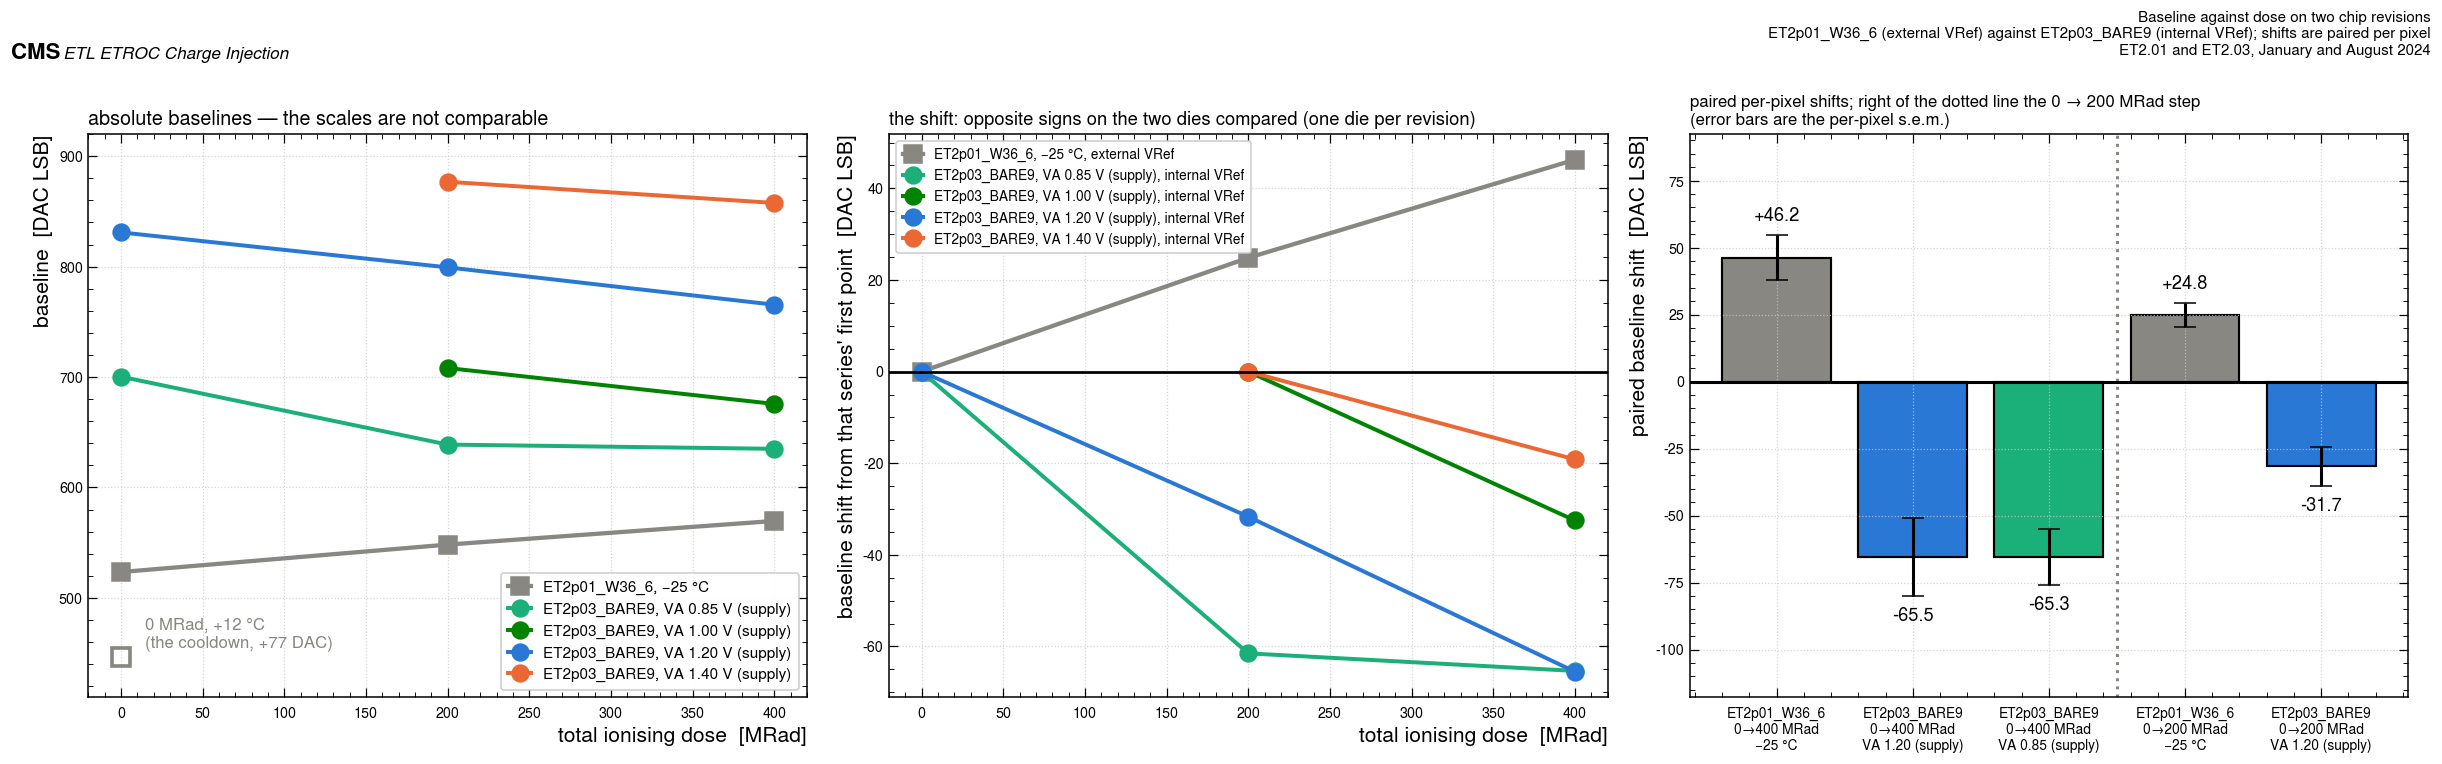

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
x01 = [0, 200, 400]
y01 = [b01[(d, -25)] for d in x01]
ax.plot(x01, y01, "-s", ms=12, lw=2.8, color=SCOL[K01], label=f"{DIE[K01]}, −25 °C")
ax.plot([0], [b01[(0, 12)]], "s", ms=12, mfc="none", mec=SCOL[K01], mew=2.4)
ax.annotate("0 MRad, +12 °C\n(the cooldown, +%.0f DAC)" % (b01[(0, -25)] - b01[(0, 12)]),
            (0, b01[(0, 12)]), textcoords="offset points", xytext=(16, 6), fontsize=11,
            color=SCOL[K01])
ax.set_ylim(410, 920)
for va, cc in zip([0.85, 1.00, 1.20, 1.40], [Q.C_AQUA, Q.C_GREEN, Q.C_BLUE, Q.C_ORANGE]):
    s = bl3[bl3.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.plot(s.dose, s.BL_mean, "-o", ms=11, lw=2.6, color=cc, label=f"{DIE[K03]}, VA {va:.2f} V (supply)")
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("baseline  [DAC LSB]")
ax.legend(fontsize=10)
ax.set_title("absolute baselines — the scales are not comparable", loc="left", fontsize=13)

ax = axs[1]
ax.plot(x01, [v - y01[0] for v in y01], "-s", ms=12, lw=2.8, color=SCOL[K01],
        label=f"{DIE[K01]}, −25 °C, external VRef")
for va, cc in zip([0.85, 1.00, 1.20, 1.40], [Q.C_AQUA, Q.C_GREEN, Q.C_BLUE, Q.C_ORANGE]):
    s = bl3[bl3.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.plot(s.dose, s.BL_mean - s.BL_mean.iloc[0], "-o", ms=11, lw=2.6, color=cc,
            label=f"{DIE[K03]}, VA {va:.2f} V (supply), internal VRef")
ax.axhline(0, color="black", lw=1.8)
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("baseline shift from that series' first point  [DAC LSB]")
ax.legend(fontsize=9, loc="upper left")
ax.set_title("the shift: opposite signs on the two dies compared (one die per revision)",
             loc="left", fontsize=12)

ax = axs[2]
# Every bar is a PAIRED per-pixel baseline shift with its standard error. The cooling shift is annotated in the left
# panel instead of drawn here: it is a temperature axis, not a dose one, and no error is exported
# for it.
def _bl(tab, **kw):
    m = tab
    for k, v in kw.items():
        m = m[m[k] == v]
    if not len(m):
        return None
    r = m.iloc[0]
    return float(r.BL_shift_paired_dac), float(r.BL_shift_sem)


bars = []
for lab, cc, v in [
    (f"{DIE[K01]}\n0→400 MRad\n−25 °C", SCOL[K01], _bl(P01, dose_from=0, dose_to=400)),
    (f"{DIE[K03]}\n0→400 MRad\nVA 1.20 (supply)", SCOL[K03], _bl(P03, va=1.20, dose_from=0, dose_to=400)),
    (f"{DIE[K03]}\n0→400 MRad\nVA 0.85 (supply)", Q.C_AQUA, _bl(P03, va=0.85, dose_from=0, dose_to=400)),
    (f"{DIE[K01]}\n0→200 MRad\n−25 °C", SCOL[K01], _bl(P01, dose_from=0, dose_to=200)),
    (f"{DIE[K03]}\n0→200 MRad\nVA 1.20 (supply)", SCOL[K03], _bl(P03, va=1.20, dose_from=0, dose_to=200)),
]:
    if v is not None:
        bars.append((lab, cc, v[0], v[1]))
x = np.arange(len(bars))
vals = [b[2] for b in bars]
errs = [b[3] for b in bars]
ax.bar(x, vals, yerr=errs, color=[b[1] for b in bars], edgecolor="black", lw=1.4, capsize=7,
       error_kw=dict(lw=2.0, ecolor="black"))
for i, (v, e) in enumerate(zip(vals, errs)):
    off = e + 4 if v > 0 else -(e + 4)
    ax.text(i, v + off, f"{v:+.1f}", ha="center", va="bottom" if v > 0 else "top", fontsize=12)
ax.axvline(2.5, color=Q.GREY, ls=":", lw=2.0)
ax.axhline(0, color="black", lw=2)
lo = min(v - e for v, e in zip(vals, errs)); hi = max(v + e for v, e in zip(vals, errs))
ax.set_ylim(lo - 0.28 * (hi - lo), hi + 0.28 * (hi - lo))
ax.set_xticks(x)
ax.set_xticklabels([b[0] for b in bars], fontsize=9)
ax.set_ylabel("paired baseline shift  [DAC LSB]")
ax.set_title("paired per-pixel shifts; right of the dotted line the 0 → 200 MRad step\n"
             "(error bars are the per-pixel s.e.m.)", loc="left", fontsize=11)
fig.tight_layout()
Q.fig_header(fig, "Baseline against dose on two chip revisions",
             tag="ET2p01_W36_6 (external VRef) against ET2p03_BARE9 (internal VRef); "
                 "shifts are paired per pixel",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig1_baseline_vs_dose")
plt.show()

### What is, and is not, separable here

**What the data says.** Over 0 → 400 MRad the ET2.01 bare die `ET2p01_W36_6`'s baseline rises by
about +46 DAC at a fixed −25 °C; the ET2.03 die **`ET2p03_BARE9`'s** falls by about −65 DAC at
VA 1.20 V and by −65 DAC at VA 0.85 V, and it falls on every rail of **that die** that has two
dose points. No second die of either revision has a usable dose step (notebook 03 section 14
explains why BARE7 does not count), so this is one die against one die. Both campaigns
resolve their own shift comfortably: notebook 01's four conditions and notebook 03's repeated
0 MRad acquisition, which reproduces its mean baseline to 0.0 DAC.

**What it does not say.** Four things change together between the two dose series, and this
comparison cannot rank them:

1. **The voltage reference** — external 1.0 V on ET2.01, the chip's own generator on ET2.03.
   This is the hypothesis the comparison was built to test. **It is now measured on the ET2.03
   side**: the campaign logged BARE9's VRef pin, and it rose by 4.7 % over 0 → 400 MRad at constant
   plate temperature (notebook 03 section 15). Section 2b below uses that number.
2. **Temperature** — −25 °C against −23.6 °C. Small, but notebook 01 measures the baseline's
   temperature coefficient as about −2.1 DAC/°C, which over 1.4 °C is only about 3 DAC, so
   temperature cannot account for a 111 DAC difference between the two shifts.
3. **Chip to chip.** Two dies, one of each revision. Notebook 03's three-rail comparison of BARE7's
   un-irradiated response against BARE9's (section 14, isolated numbers only) shows the chip-to-chip
   spread in absolute gain is not small; nothing tests the *sign* of the baseline shift on a second
   die, because BARE7's dose is unknown.
4. **Dose rate, facility and annealing history**, none of which is recorded on either campaign.

The one statement that survives all four is the operational one, and both campaigns reach it
independently: **referred to each condition's own baseline the turn-off curves coincide**, so
re-running autocalibration and working at `BL + 20` recovers the response whichever way the
baseline moved. That is section 4.

### 2b. The reference, measured: what the VRef log does to the ET2.03 baseline and gain

Until the campaign's monitoring logs were located this subsection was an estimate under an
assumption. It is now built on a **measurement**: notebook 03 section 15 reads the VRef pin of
`ET2p03_BARE9` through the whole irradiation and finds it **rose** by +19.5 mV after 200 MRad and
+40.3 mV (+4.66 %) after 400 MRad, at a plate temperature constant to better than 1 °C. One
assumption remains, and it is stated on every number: **the threshold DAC full scale is
proportional to the VRef pin voltage**, so a rise of $f$ in the reference lowers the code of an
unchanged analog level by the factor $1/(1+f)$ and makes a gain measured in DAC per fC read low by
$f$. The DAC transfer function itself has never been measured (open question 1).

On the **ET2.01** side the reference was external and fixed, so its +46 DAC baseline rise at −25 °C
is front-end drift alone. The cell below therefore compares *front end against front end* after
the ET2.03 number has had its reference part removed, and *intrinsic gain against intrinsic gain*.
The temperature cross-check from `BARE4` (the never-irradiated sister die whose VRef was logged
against chamber temperature, notebook 00 section 7.6) is kept: it bounds how much of the ET2.03
VRef change could be temperature rather than dose.

In [5]:
pr01 = P01[(P01.dose_from == 0) & (P01.dose_to == 400)].iloc[0]
pr03b = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 400)].iloc[0]
v0 = float(VREF03[VREF03.dose_MRad == 0].vref_V.iloc[0])
v2 = float(VREF03[VREF03.dose_MRad == 200].vref_V.iloc[0])
v4 = float(VREF03[VREF03.dose_MRad == 400].vref_V.iloc[0])
f400 = v4 / v0 - 1
f200 = v2 / v0 - 1
dec = SCALE03.set_index("quantity")
map400 = dec.loc["baseline, 256-px map, 0->400 MRad"]
six400 = dec.loc["baseline, 6-px in-config, VA 1.20 supply, 0->400 MRad"]
s01, e01 = float(pr01.BL_shift_paired_dac), float(pr01.BL_shift_sem)
s03, e03 = float(pr03b.BL_shift_paired_dac), float(pr03b.BL_shift_sem)
print("ET2.03 BARE9 internal reference (MEASURED, notebook 03 section 15):")
print("  0 MRad %.4f V   200 MRad %.4f V (%+.2f %%)   400 MRad %.4f V (%+.2f %%)" % (v0, v2, 100 * f200, v4, 100 * f400))
print("\nbaseline shift, 0 -> 400 MRad, paired per pixel:")
print("  ET2.01 W36_6, external VRef, -25 C      : %+7.2f +- %.2f DAC  -> front end %+.1f DAC (the reference is fixed)"
      % (s01, e01, s01))
print("  ET2.03 BARE9, internal VRef, VA 1.20    : %+7.2f +- %.2f DAC" % (s03, e03))
print("     of which reference scale (DAC full scale ∝ VRef): %+.1f DAC" % six400.reference_scale_dac)
print("     front end, left over                             : %+.1f +- %.1f DAC" % (six400.front_end_dac, e03))
print("  the same on the 256-pixel autocalibration maps      : measured %+.1f, reference %+.1f, front end %+.1f DAC"
      % (map400.measured_dac, map400.reference_scale_dac, map400.front_end_dac))
print("\n  So even after the measured reference rise is removed, the two front ends drift in OPPOSITE")
print("  directions with dose (%+.0f DAC on the ET2.01 die, %+.0f DAC on the ET2.03 die). The sign" % (s01, six400.front_end_dac))
print("  difference is not the reference. It remains a one-die-per-revision observation.")
# gain
g03m, g03e = float(pr03b.gain_change_pct), float(100 * pr03b.gain_ratio_sem)
g01m, g01e = float(pr01.gain_change_pct), float(100 * pr01.gain_ratio_sem)
print("\npreamp gain, 0 -> 400 MRad, paired per pixel:")
print("  ET2.01 W36_6 (fixed reference)          : %+.1f +- %.1f %%" % (g01m, g01e))
print("  ET2.03 BARE9 measured in DAC/fC         : %+.1f +- %.1f %%" % (g03m, g03e))
print("  ET2.03 BARE9 intrinsic (mV/fC), + %.1f %%: %+.1f +- %.1f %%   -- consistent with no loss" % (100 * f400, g03m + 100 * f400, g03e))
print("  difference ET2.01 - ET2.03 intrinsic    : %.1f points against a combined error of %.1f" % (abs(g01m - (g03m + 100 * f400)), np.hypot(g01e, g03e)))
# temperature cross-check from BARE4
dT_C = 1.4
vref_slope = float(VFIT[VFIT.instrument == "VRef"].slope_mV_per_C.iloc[0])
vref_slope_e = float(VFIT[VFIT.instrument == "VRef"].err_mV_per_C.iloc[0])
print("\ntemperature cross-check (BARE4, notebook 00 section 7.6): VRef %+.3f +- %.3f mV/C, so the ~%.1f C"
      % (vref_slope, vref_slope_e, dT_C))
print("  campaign-to-campaign difference is %+.2f mV, and the <1 C plate stability within the ET2.03"
      % (vref_slope * dT_C))
print("  campaign is < %.1f mV -- both negligible against the %+.1f mV measured rise." % (vref_slope * 1.0, 1e3 * (v4 - v0)))
RESULTS_2B_VREF = dict(vref_slope_mV_per_C=vref_slope, vref_slope_err_mV_per_C=vref_slope_e, dT_C=dT_C,
                       vref_shift_from_dT_mV=vref_slope * dT_C, source_die="ET2p03_BARE4")
# The X-ray footprints. Both campaigns' 256-pixel maps show a partial spot (notebook 01 §11.2, notebook 03 §15b):
# January covered rows 0-3 of W36_6 (nine of the twelve pixels inside), August covered rows ~6-15 of
# BARE9 (two of the six pixels inside). Un-irradiated rows are a null test of the reference: on the
# fixed external reference they did not move; on the internal reference they moved by exactly the
# VRef prediction. The front-end drift is read from the rows INSIDE each spot.
FP01 = pd.read_csv(Q.OUTDIR / "bare_footprint_split.csv")
FP03 = pd.read_csv(Q.OUTDIR / "et2p03_footprint_split.csv")
FR03 = pd.read_csv(Q.OUTDIR / "et2p03_footprint_by_row.csv")
FR01 = pd.read_csv(Q.OUTDIR / "bare_footprint_by_row.csv")
in01 = FP01[(FP01.pixels.str.startswith("inside")) & (FP01.dose_to == 400)].iloc[0]
out01 = FP01[(FP01.pixels.str.startswith("outside")) & (FP01.dose_to == 400)].iloc[0]
in03 = FP03[(FP03.pixels.str.startswith("inside")) & (FP03.dose_to == 400)].iloc[0]
out03 = FP03[(FP03.pixels.str.startswith("outside")) & (FP03.dose_to == 400)].iloc[0]
print("\nTHE FOOTPRINT SPLIT, 0 -> 400 MRad, in-configuration pixels:")
print("  ET2.01 W36_6  inside the spot (%d px): baseline %+.1f +- %.1f DAC = front end (reference fixed);  outside (%d px): %+.1f +- %.1f (null)"
      % (in01.n_pixels, in01.bl_shift_dac, in01.bl_shift_sem, out01.n_pixels, out01.bl_shift_dac, out01.bl_shift_sem))
print("  ET2.03 BARE9  inside the spot (%d px): baseline %+.1f DAC = reference %+.1f + front end %+.1f;  outside (%d px): %+.1f vs reference-only %+.1f"
      % (in03.n_pixels, in03.bl_shift_dac, in03.reference_scale_dac, in03.front_end_dac, out03.n_pixels, out03.bl_shift_dac, out03.reference_scale_dac))
print("  256-pixel maps, rows inside each spot: ET2.01 %+.1f DAC at 200 MRad (400 MRad map not saved); ET2.03 %+.1f at 200, %+.1f at 400 (front end %+.1f, %+.1f)"
      % (FR01[FR01.row <= 3].shift_0_200_dac.mean(), FR03[FR03.row >= 7].shift_0_200_dac.mean(), FR03[FR03.row >= 7].shift_0_400_dac.mean(),
         FR03[FR03.row >= 7].shift_0_200_dac.mean() - FR03.reference_only_prediction_0_200.iloc[0], FR03[FR03.row >= 7].shift_0_400_dac.mean() - FR03.reference_only_prediction_0_400.iloc[0]))
print("  Front end against front end on the irradiated rows: ET2.01 UP, ET2.03 DOWN. The sign difference is real and")
print("  larger than the mixed-pixel numbers suggested; it is still one die per revision.")
print("  Gain inside each spot: ET2.01 %+.1f +- %.1f %% (%d px); ET2.03 %+.1f +- %.1f %% measured, %+.1f %% reference-corrected (%d px, too few)"
      % (in01.gain_change_pct, in01.gain_change_sem_pct, in01.n_pixels, in03.gain_change_pct, in03.gain_change_sem_pct, in03.gain_intrinsic_pct, in03.n_pixels))
RESULTS_2B_FOOTPRINT = dict(et2p01_inside_bl_0_400=float(in01.bl_shift_dac), et2p01_outside_bl_0_400=float(out01.bl_shift_dac),
                            et2p03_inside_bl_0_400=float(in03.bl_shift_dac), et2p03_inside_front_end_0_400=float(in03.front_end_dac),
                            et2p03_outside_bl_0_400=float(out03.bl_shift_dac), et2p03_outside_reference_prediction=float(out03.reference_scale_dac))
RESULTS_2B = dict(**RESULTS_2B_FOOTPRINT, vref_0MRad_V=v0, vref_200MRad_V=v2, vref_400MRad_V=v4, vref_change_0_to_400_pct=100 * f400,
                  bl_shift_et2p01_dac=s01, bl_shift_et2p01_sem=e01,
                  bl_shift_et2p03_dac=s03, bl_shift_et2p03_sem=e03,
                  et2p03_reference_scale_dac=float(six400.reference_scale_dac),
                  et2p03_front_end_dac=float(six400.front_end_dac),
                  et2p03_map256_measured_dac=float(map400.measured_dac),
                  et2p03_map256_reference_scale_dac=float(map400.reference_scale_dac),
                  et2p03_map256_front_end_dac=float(map400.front_end_dac),
                  gain_measured_pct=g03m, gain_intrinsic_pct=g03m + 100 * f400, gain_et2p01_pct=g01m,
                  assumption="DAC full scale proportional to the VRef pin voltage")
pd.DataFrame([RESULTS_2B]).to_csv(Q.OUTDIR / "xcamp_reference_drift_estimate.csv", index=False)

ET2.03 BARE9 internal reference (MEASURED, notebook 03 section 15):
  0 MRad 0.8638 V   200 MRad 0.8833 V (+2.26 %)   400 MRad 0.9040 V (+4.66 %)

baseline shift, 0 -> 400 MRad, paired per pixel:
  ET2.01 W36_6, external VRef, -25 C      :  +46.25 +- 8.38 DAC  -> front end +46.2 DAC (the reference is fixed)
  ET2.03 BARE9, internal VRef, VA 1.20    :  -65.50 +- 14.59 DAC
     of which reference scale (DAC full scale ∝ VRef): -37.0 DAC
     front end, left over                             : -28.5 +- 14.6 DAC
  the same on the 256-pixel autocalibration maps      : measured -80.1, reference -37.1, front end -42.9 DAC

  So even after the measured reference rise is removed, the two front ends drift in OPPOSITE
  directions with dose (+46 DAC on the ET2.01 die, -28 DAC on the ET2.03 die). The sign
  difference is not the reference. It remains a one-die-per-revision observation.

preamp gain, 0 -> 400 MRad, paired per pixel:
  ET2.01 W36_6 (fixed reference)          : -6.5 +- 3.2 %
  ET2.03 

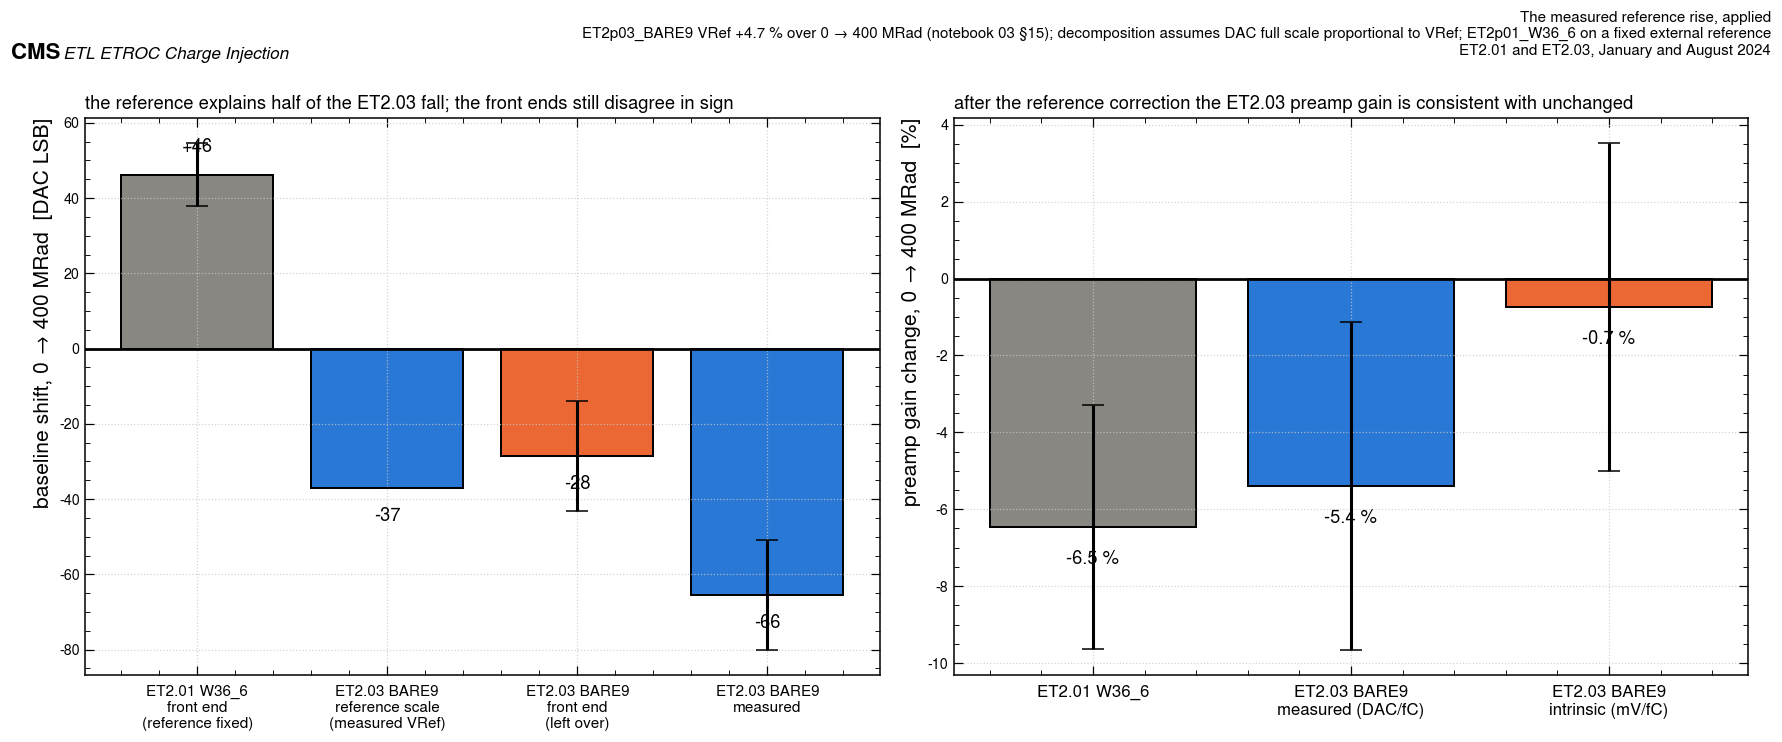

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.2))
ax = axs[0]
labs = ["ET2.01 W36_6\nfront end\n(reference fixed)", "ET2.03 BARE9\nreference scale\n(measured VRef)", "ET2.03 BARE9\nfront end\n(left over)", "ET2.03 BARE9\nmeasured"]
vals = [s01, float(six400.reference_scale_dac), float(six400.front_end_dac), s03]
errs = [e01, 0, e03, e03]
ax.bar(range(4), vals, yerr=errs, color=[Q.GREY, Q.C_BLUE, Q.C_ORANGE, Q.C_BLUE], edgecolor="black", lw=1.3, capsize=7,
       error_kw=dict(lw=2, ecolor="black"))
for i, v in enumerate(vals):
    ax.text(i, v + (5 if v > 0 else -5), f"{v:+.0f}", ha="center", va="bottom" if v > 0 else "top", fontsize=12)
ax.axhline(0, color="black", lw=1.8)
ax.set_xticks(range(4)); ax.set_xticklabels(labs, fontsize=10)
ax.set_ylabel("baseline shift, 0 → 400 MRad  [DAC LSB]")
ax.set_title("the reference explains half of the ET2.03 fall; the front ends still disagree in sign", loc="left", fontsize=12)
ax = axs[1]
labs2 = ["ET2.01 W36_6", "ET2.03 BARE9\nmeasured (DAC/fC)", "ET2.03 BARE9\nintrinsic (mV/fC)"]
vals2 = [g01m, g03m, g03m + 100 * f400]
errs2 = [g01e, g03e, g03e]
ax.bar(range(3), vals2, yerr=errs2, color=[Q.GREY, Q.C_BLUE, Q.C_ORANGE], edgecolor="black", lw=1.3, capsize=7,
       error_kw=dict(lw=2, ecolor="black"))
for i, v in enumerate(vals2):
    ax.text(i, v - 0.6, f"{v:+.1f} %", ha="center", va="top", fontsize=12)
ax.axhline(0, color="black", lw=1.8)
ax.set_xticks(range(3)); ax.set_xticklabels(labs2, fontsize=11)
ax.set_ylabel("preamp gain change, 0 → 400 MRad  [%]")
ax.set_title("after the reference correction the ET2.03 preamp gain is consistent with unchanged", loc="left", fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "The measured reference rise, applied",
             tag=f"ET2p03_BARE9 VRef +{100 * f400:.1f} % over 0 → 400 MRad (notebook 03 §15); decomposition assumes DAC full scale proportional to VRef; "
                 "ET2p01_W36_6 on a fixed external reference", scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig7_reference_measured")
plt.show()

**What would sharpen it.** A bench threshold-DAC transfer function against an external voltmeter at
several VA settings and before and after irradiation replaces the one assumption left here (open
question 1). A second die of the same revision with a *known* dose would test whether the
front-end sign is a die property or a revision property; BARE7 cannot, because its dose is unknown.

What it already settles: the ET2.03 internal reference does move with dose, upward, by a few per
cent; the preamp gain of that die, once the reference is removed, did not measurably change; and
the remaining baseline drift of its front end has the opposite sign to the ET2.01 die's. **The
X-ray footprints make the last point sharper, not weaker**: the un-irradiated rows of each die are a
null test that both pass (no motion on the fixed reference; exactly the VRef prediction on the
internal one), and the irradiated rows give front-end drifts of about +33 DAC (ET2.01, 200 MRad) and
−67 DAC (ET2.03, 400 MRad) — opposite signs, one die each.

## 3. Gain against dose, and the rail axis that only ET2.03 has

Gain is the slope of turn-off against injected charge, `qinj_common.gain_fit` on all three data
sets, y-error 0.5 DAC, fitted from 8 fC upward on all three (to 27 fC on the January sets, to
22 fC on the August one, which injected nothing higher).

In [7]:
g01 = G01.set_index(["dose", "temp"])
gh = GH.set_index("config")
g03 = G03[(G03.chip == "ET2p03_BARE9") & G03.dose.notna()]
rows = []
for d in [0, 200, 400]:
    rows.append(dict(data_set=K01, condition=f"{d} MRad, −25 °C", dose=d,
                     gain_dac_per_fc=g01.loc[(d, -25), "gain_dac_per_fc"],
                     gain_sem=g01.loc[(d, -25), "gain_sem"],
                     gain_mv_per_fc=g01.loc[(d, -25), "gain_mv_per_fc"],
                     rel_to_0MRad=g01.loc[(d, -25), "gain_dac_per_fc"] / g01.loc[(0, -25), "gain_dac_per_fc"]))
rows.append(dict(data_set=K02, condition="0 MRad, 0 °C, HV 210 V", dose=0,
                 gain_dac_per_fc=gh.loc[HYB_PRIMARY, "gain_dac_per_fc"],
                 gain_sem=gh.loc[HYB_PRIMARY, "gain_sem"],
                 gain_mv_per_fc=gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] * Q.LSB_MV, rel_to_0MRad=np.nan))
for _, r in g03[g03.va == 1.20].sort_values("dose").iterrows():
    ref = float(g03[(g03.va == 1.20) & (g03.dose == 0)].gain_dac_per_fc.iloc[0])
    rows.append(dict(data_set=K03, condition=f"{int(r.dose)} MRad, VA 1.20 V (supply)", dose=r.dose,
                     gain_dac_per_fc=r.gain_dac_per_fc, gain_sem=r.gain_sem,
                     gain_mv_per_fc=r.gain_mv_per_fc, rel_to_0MRad=r.gain_dac_per_fc / ref))
GCMP = pd.DataFrame(rows)
GCMP.to_csv(Q.OUTDIR / "xcamp_gain_vs_dose.csv", index=False)
print(GCMP.round(3).to_string(index=False))

# Row 2 of the summary compares a dose ratio between the campaigns, so both sides must be the
# SAME estimator. Notebook 01 exports its 0 -> 400 MRad step both ways: the ratio of the pooled
# per-condition means (no error, because the pixel-to-pixel spread swamps the change) and the
# paired per-pixel ratio over the twelve pixels that exist at both doses. Notebook 03 exports only
# the paired one. The paired pair is what is carried; the pooled ET2.01 number is printed beside
# it so the difference between the two estimators is visible rather than hidden.
pooled01 = 100 * (g01.loc[(400, -25), "gain_dac_per_fc"] / g01.loc[(0, -25), "gain_dac_per_fc"] - 1)
pr01 = P01[(P01.dose_from == 0) & (P01.dose_to == 400)]
f01 = float(pr01.gain_change_pct.iloc[0])
f01e = float(100 * pr01.gain_ratio_sem.iloc[0])
n01p = int(pr01.n_pixels.iloc[0])
pr = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 400)]
f03 = float(pr.gain_change_pct.iloc[0])
f03e = float(100 * pr.gain_ratio_sem.iloc[0])
n03p = int(pr.n_pixels.iloc[0])
print("\ngain change 0 -> 400 MRad, the paired per-pixel estimator on both campaigns")
print("  ET2.01 bare, −25 °C,    paired over %2d pixels: %+.1f +- %.1f %%" % (n01p, f01, f01e))
print("  ET2.03 bare, VA 1.20 V, paired over %2d pixels: %+.1f +- %.1f %%" % (n03p, f03, f03e))
print("  (ET2.01 as a ratio of pooled means, the estimator this notebook used to quote: %+.1f %%,"
      % pooled01)
print("   no error — the two differ by %.1f points, which is the pairing, not the data)"
      % abs(f01 - pooled01))
print("  ET2.03 200 -> 400 MRad steps, all four rails: %s %%"
      % [round(v, 1) for v in P03[(P03.dose_from == 200)].gain_change_pct])
print("\nThe two revisions lose the same few per cent of gain over 400 MRad, while their baselines")
print("moved in opposite directions by comparable amounts. The dose effect on the charge response")
print("and the dose effect on the threshold reference are therefore not the same effect.")
print("\nThe ET2.03 analog-rail axis, which neither January campaign has:")
r200 = g03[g03.dose == 200].sort_values("va")
print("  VA %s V -> gain %s DAC/fC (a factor %.2f over the range)"
      % ([f"{v:.2f}" for v in r200.va], [round(v, 2) for v in r200.gain_dac_per_fc],
         r200.gain_dac_per_fc.iloc[-1] / r200.gain_dac_per_fc.iloc[0]))
print("  and the same 400 MRad dose costs %+.1f %% at VA 0.85 V against %+.1f %% at VA 1.20 V"
      % (float(P03[(P03.va == 0.85) & (P03.dose_from == 0) & (P03.dose_to == 400)].gain_change_pct.iloc[0]), f03))

     data_set                    condition  dose  gain_dac_per_fc  gain_sem  gain_mv_per_fc  rel_to_0MRad
  ET2.01 bare               0 MRad, −25 °C   0.0            8.691     0.861           3.395         1.000
  ET2.01 bare             200 MRad, −25 °C 200.0            8.315     0.826           3.248         0.957
  ET2.01 bare             400 MRad, −25 °C 400.0            8.216     0.826           3.209         0.945
ET2.01 + LGAD       0 MRad, 0 °C, HV 210 V   0.0            5.957     0.366           2.327           NaN
  ET2.03 bare   0 MRad, VA 1.20 V (supply)   0.0            8.256     1.188           3.225         1.000
  ET2.03 bare 200 MRad, VA 1.20 V (supply) 200.0            8.239     1.209           3.218         0.998
  ET2.03 bare 400 MRad, VA 1.20 V (supply) 400.0            7.921     1.313           3.094         0.959

gain change 0 -> 400 MRad, the paired per-pixel estimator on both campaigns
  ET2.01 bare, −25 °C,    paired over 12 pixels: -6.5 +- 3.2 %
  ET2.03 bar

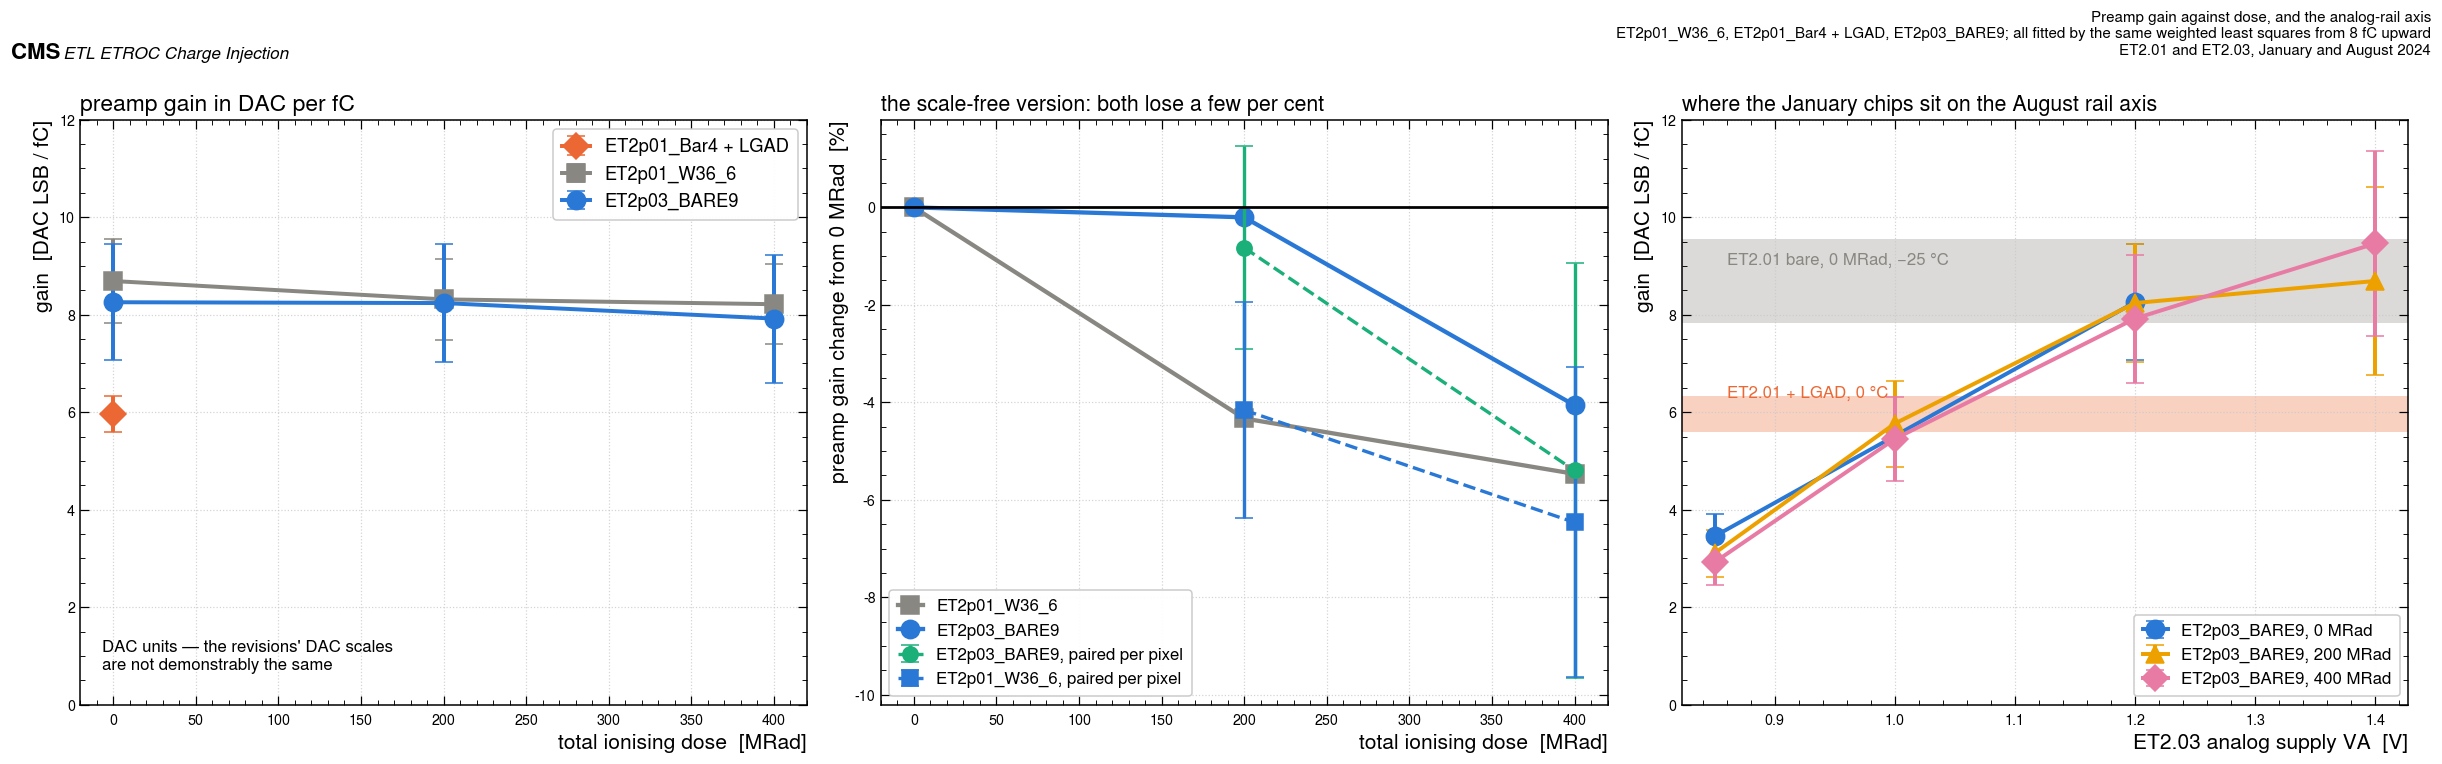

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for ds, sub in GCMP.groupby("data_set"):
    sub = sub.sort_values("dose")
    ax.errorbar(sub.dose, sub.gain_dac_per_fc, yerr=sub.gain_sem, fmt="-", marker=SMK[ds], ms=12,
                lw=2.6, color=SCOL[ds], capsize=6, label=DIE[ds])
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.set_ylim(0, 12)
ax.legend(fontsize=12)
ax.text(0.03, 0.06, "DAC units — the revisions' DAC scales\nare not demonstrably the same",
        transform=ax.transAxes, fontsize=11)
ax.set_title("preamp gain in DAC per fC", loc="left", fontsize=15)

ax = axs[1]
for ds, sub in GCMP.dropna(subset=["rel_to_0MRad"]).groupby("data_set"):
    sub = sub.sort_values("dose")
    ax.plot(sub.dose, 100 * (sub.rel_to_0MRad - 1), "-", marker=SMK[ds], ms=12, lw=2.8,
            color=SCOL[ds], label=DIE[ds])
pp = P03[(P03.va == 1.20) & (P03.dose_from == 0)].sort_values("dose_to")
ax.errorbar(pp.dose_to, pp.gain_change_pct, yerr=100 * pp.gain_ratio_sem, fmt="o--", ms=10,
            lw=2.2, color=Q.C_AQUA, capsize=6, label=f"{DIE[K03]}, paired per pixel")
pp1 = P01[P01.dose_from == 0].sort_values("dose_to")
ax.errorbar(pp1.dose_to, pp1.gain_change_pct, yerr=100 * pp1.gain_ratio_sem, fmt="s--", ms=10,
            lw=2.2, color=Q.C_BLUE, capsize=6, label=f"{DIE[K01]}, paired per pixel")
ax.axhline(0, color="black", lw=1.8)
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("preamp gain change from 0 MRad  [%]")
ax.legend(fontsize=11)
ax.set_title("the scale-free version: both lose a few per cent", loc="left", fontsize=14)

ax = axs[2]
for dose, cc, mk in [(0.0, Q.C_BLUE, "o"), (200.0, Q.C_YELLOW, "^"), (400.0, Q.C_MAG, "D")]:
    s = g03[g03.dose == dose].sort_values("va")
    if not len(s):
        continue
    ax.errorbar(s.va, s.gain_dac_per_fc, yerr=s.gain_sem, fmt="-", marker=mk, ms=12, lw=2.6,
                color=cc, capsize=6, label=f"{DIE[K03]}, {int(dose)} MRad")
ax.axhspan(g01.loc[(0, -25), "gain_dac_per_fc"] - g01.loc[(0, -25), "gain_sem"],
           g01.loc[(0, -25), "gain_dac_per_fc"] + g01.loc[(0, -25), "gain_sem"],
           color=SCOL[K01], alpha=0.30, lw=0)
ax.text(0.86, g01.loc[(0, -25), "gain_dac_per_fc"] + 0.35, "ET2.01 bare, 0 MRad, −25 °C",
        fontsize=11, color=SCOL[K01])
ax.axhspan(gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] - gh.loc[HYB_PRIMARY, "gain_sem"],
           gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] + gh.loc[HYB_PRIMARY, "gain_sem"],
           color=SCOL[K02], alpha=0.30, lw=0)
ax.text(0.86, gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] + 0.35, "ET2.01 + LGAD, 0 °C",
        fontsize=11, color=SCOL[K02])
ax.set_xlabel("ET2.03 analog supply VA  [V]")
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.set_ylim(0, 12)
ax.legend(fontsize=11, loc="lower right")
ax.set_title("where the January chips sit on the August rail axis", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Preamp gain against dose, and the analog-rail axis",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; "
                 "all fitted by the same weighted least squares from 8 fC upward",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig2_gain")
plt.show()

The right-hand panel is the one to be careful with. It looks as though the ET2.01 chips "are" at
some particular VA on the ET2.03 curve, and that is **not** what it shows: the January chips'
rails were not recorded, their DAC scale is set by a different reference, and their pixel sets
and temperatures differ. What it does show is that **the entire spread between the three data
sets in DAC per fC — a factor of about 1.7 — is smaller than the range one chip covers when its
own analog supply is moved from 0.85 to 1.40 V.** Any comparison of absolute gain between
campaigns that do not record their rails is therefore weakly constrained at best.

## 4. Turn-off referred to baseline, against charge

This is the comparison that is closest to scale-free: each curve is `turn-off − BL` for the
condition it was measured in, so a common offset in the DAC scale cancels. A *multiplicative*
scale difference does not cancel, which is why the ET2.03 rail dependence is drawn alongside.

In [9]:
o01 = O01[(O01.dose == 0) & (O01.temp == 12)].groupby("charge").trig_turnoff_offset.agg(["mean", "std"])
o01m = O01[(O01.dose == 400) & (O01.temp == -25)].groupby("charge").trig_turnoff_offset.agg(["mean", "std"])
oh = OH[OH.config == HYB_PRIMARY].groupby("charge_fC").trig_turnoff_offset.agg(["mean", "std"])
o03 = O03[O03.config == CFG03].groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
o03m = O03[O03.config == G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 400) & (G03.va == 1.20)].config.iloc[0]]
o03m = o03m.groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
TOFF = pd.concat([o01.assign(data_set=K01, condition="0 MRad, +12 °C"),
                  o01m.assign(data_set=K01, condition="400 MRad, −25 °C"),
                  oh.assign(data_set=K02, condition="0 MRad, 0 °C, HV 210 V"),
                  o03.assign(data_set=K03, condition="0 MRad, VA 1.20 V"),
                  o03m.assign(data_set=K03, condition="400 MRad, VA 1.20 V")])
TOFF.index.name = "charge_fC"
TOFF = TOFF.reset_index().rename(columns={"mean": "turnoff_offset_mean", "std": "pixel_rms"})
TOFF.to_csv(Q.OUTDIR / "xcamp_turnoff_vs_charge.csv", index=False)
print(TOFF.round(2).to_string(index=False))
common = sorted(set(o01.index) & set(oh.index) & set(o03.index))
print("\ncharges measured by all three: %s fC" % common)
print("turn-off above baseline there [DAC]:")
for c in common:
    print("  %2d fC:  ET2.01 bare %6.1f   ET2.01+LGAD %6.1f   ET2.03 bare %6.1f   "
          "(hybrid/bare %.2f, ET2.03/ET2.01 %.2f)"
          % (c, o01.loc[c, "mean"], oh.loc[c, "mean"], o03.loc[c, "mean"],
             oh.loc[c, "mean"] / o01.loc[c, "mean"], o03.loc[c, "mean"] / o01.loc[c, "mean"]))

 charge_fC  turnoff_offset_mean  pixel_rms      data_set              condition
       5.0                45.94       6.24   ET2.01 bare         0 MRad, +12 °C
       6.0                47.34       7.41   ET2.01 bare         0 MRad, +12 °C
       8.0                55.21      14.98   ET2.01 bare         0 MRad, +12 °C
      15.0               116.03      37.23   ET2.01 bare         0 MRad, +12 °C
      22.0               187.77      58.03   ET2.01 bare         0 MRad, +12 °C
      27.0               232.09      71.31   ET2.01 bare         0 MRad, +12 °C
       5.0                49.77       7.31   ET2.01 bare       400 MRad, −25 °C
       6.0                52.17       9.60   ET2.01 bare       400 MRad, −25 °C
       8.0                60.12      19.94   ET2.01 bare       400 MRad, −25 °C
      15.0               117.39      43.85   ET2.01 bare       400 MRad, −25 °C
      22.0               177.44      60.68   ET2.01 bare       400 MRad, −25 °C
      27.0               215.11      72.

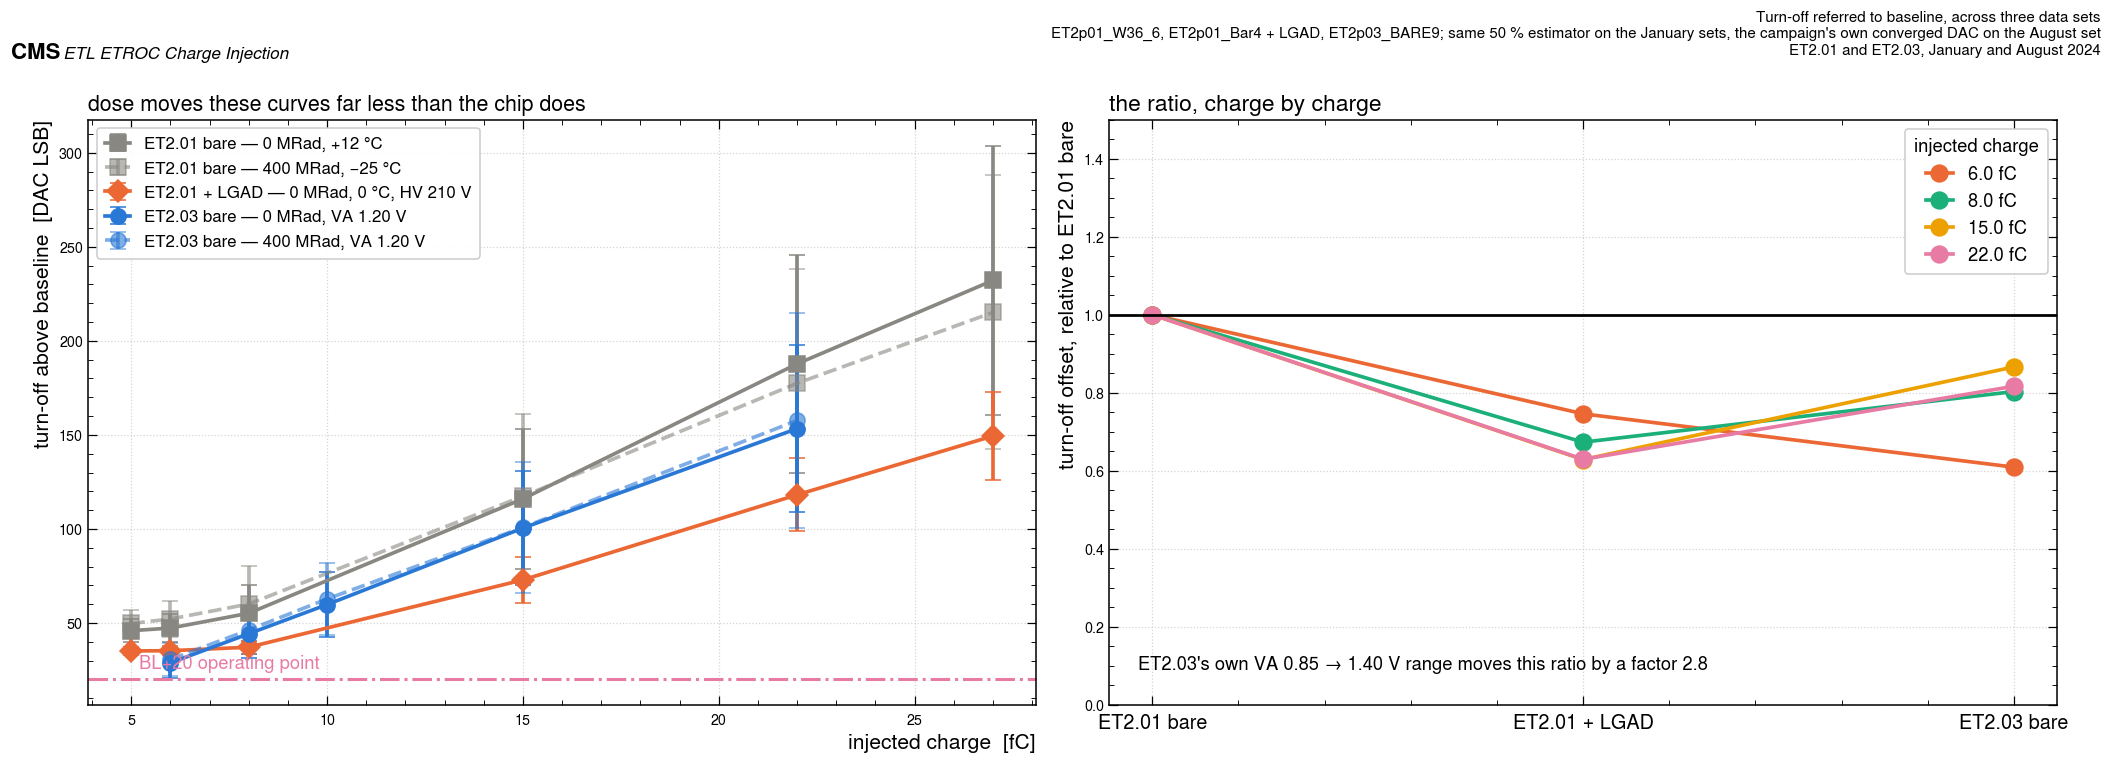

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
for tab, ds, cond, ls in [(o01, K01, "0 MRad, +12 °C", "-"), (o01m, K01, "400 MRad, −25 °C", "--"),
                          (oh, K02, "0 MRad, 0 °C, HV 210 V", "-"),
                          (o03, K03, "0 MRad, VA 1.20 V", "-"), (o03m, K03, "400 MRad, VA 1.20 V", "--")]:
    ax.errorbar(tab.index, tab["mean"], yerr=tab["std"], fmt=ls, marker=SMK[ds], ms=10, lw=2.4,
                color=SCOL[ds], capsize=5, alpha=1.0 if ls == "-" else 0.6,
                label=f"{ds} — {cond}")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.text(5.2, Q.OP_OFFSET + 6, "BL+20 operating point", color=Q.C_MAG, fontsize=12)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=11, loc="upper left")
ax.set_title("dose moves these curves far less than the chip does", loc="left", fontsize=14)

ax = axs[1]
for c, cc in zip(common, [Q.CCOL[x] for x in common]):
    vals = [o01.loc[c, "mean"], oh.loc[c, "mean"], o03.loc[c, "mean"]]
    ax.plot([0, 1, 2], [v / vals[0] for v in vals], "-o", ms=11, lw=2.4, color=cc, label=f"{c} fC")
ax.axhline(1.0, color="black", lw=1.8)
g03_va = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 200)].sort_values("va")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels([K01, K02, K03], fontsize=13)
ax.set_ylabel("turn-off offset, relative to ET2.01 bare")
ax.legend(fontsize=12, title="injected charge", title_fontsize=12)
ax.set_ylim(0, 1.5)
ax.text(0.03, 0.06, "ET2.03's own VA 0.85 → 1.40 V range moves this ratio by a factor %.1f"
        % (g03_va.gain_dac_per_fc.iloc[-1] / g03_va.gain_dac_per_fc.iloc[0]),
        transform=ax.transAxes, fontsize=12)
ax.set_title("the ratio, charge by charge", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Turn-off referred to baseline, across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; same 50 % estimator on the "
                 "January sets, the campaign's own converged DAC on the August set",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig3_turnoff")
plt.show()

## 5. TOT against charge at the operating point

TOT is the charge proxy the offline time-walk correction consumes, so its response to a known
charge is the most directly transferable measurement in this folder — and it is the one that
transfers worst.

**RFSel is not recorded on any of the three data sets.** It sets the preamplifier feedback
resistance and therefore fixes TOT directly. Every difference in this section is therefore an
upper bound on a real difference, and none of it can be attributed to the sensor, the revision
or the dose without knowing RFSel.

In [11]:
t01 = T01[T01.offset == 20].set_index("charge_fC")
th = TH[TH.offset == 20].set_index("charge_fC")
t03 = T03[(T03.config == CFG03) & (T03.offset == 20)].set_index("charge_fC")
TOTC = pd.concat([
    t01[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K01),
    th[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K02),
    t03[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K03)])
TOTC.to_csv(Q.OUTDIR / "xcamp_tot_at_bl20.csv")
print(TOTC.round(3).to_string())
print("\nat the charges all three measured:")
for c in common:
    print("  %2d fC:  ET2.01 bare %5.1f code (%.2f ns)   ET2.01+LGAD %5.1f (%.2f ns)   "
          "ET2.03 bare %5.1f (%.2f ns)"
          % (c, t01.loc[c, "tot_code_mean"], t01.loc[c, "tot_ns_mean"],
             th.loc[c, "tot_code_mean"], th.loc[c, "tot_ns_mean"],
             t03.loc[c, "tot_code_mean"], t03.loc[c, "tot_ns_mean"]))
print("\nIn nanoseconds the two bare dies agree to within about %.0f %% at 15 fC, while the hybrid"
      % abs(100 * (t03.loc[15, "tot_ns_mean"] / t01.loc[15, "tot_ns_mean"] - 1)))
print("sits %.1f times higher. TOT in *codes* is not comparable across data sets at all, because"
      % (th.loc[15, "tot_code_mean"] / t01.loc[15, "tot_code_mean"]))
print("one code is 3.125 ns / CAL and CAL differs: %.0f, %.0f and %.0f on the three."
      % (B01["cal_median"], CAL_HYB, B03["cal_median"]))

           tot_code_mean  tot_code_pixel_rms  tot_ns_mean  n_pixels       data_set
charge_fC                                                                         
5.0               26.851              10.817        0.988         9    ET2.01 bare
6.0               32.017               9.297        1.173        12    ET2.01 bare
8.0               41.826               4.725        1.532        12    ET2.01 bare
15.0              49.873               2.191        1.830        12    ET2.01 bare
22.0              52.288               2.080        1.920        12    ET2.01 bare
27.0              53.399               2.274        1.961        12    ET2.01 bare
5.0               24.136               4.522        0.868         5  ET2.01 + LGAD
6.0               40.931              12.611        1.462         8  ET2.01 + LGAD
8.0               60.028              11.053        2.147         9  ET2.01 + LGAD
15.0              84.939               6.374        3.041         9  ET2.01 + LGAD
22.0

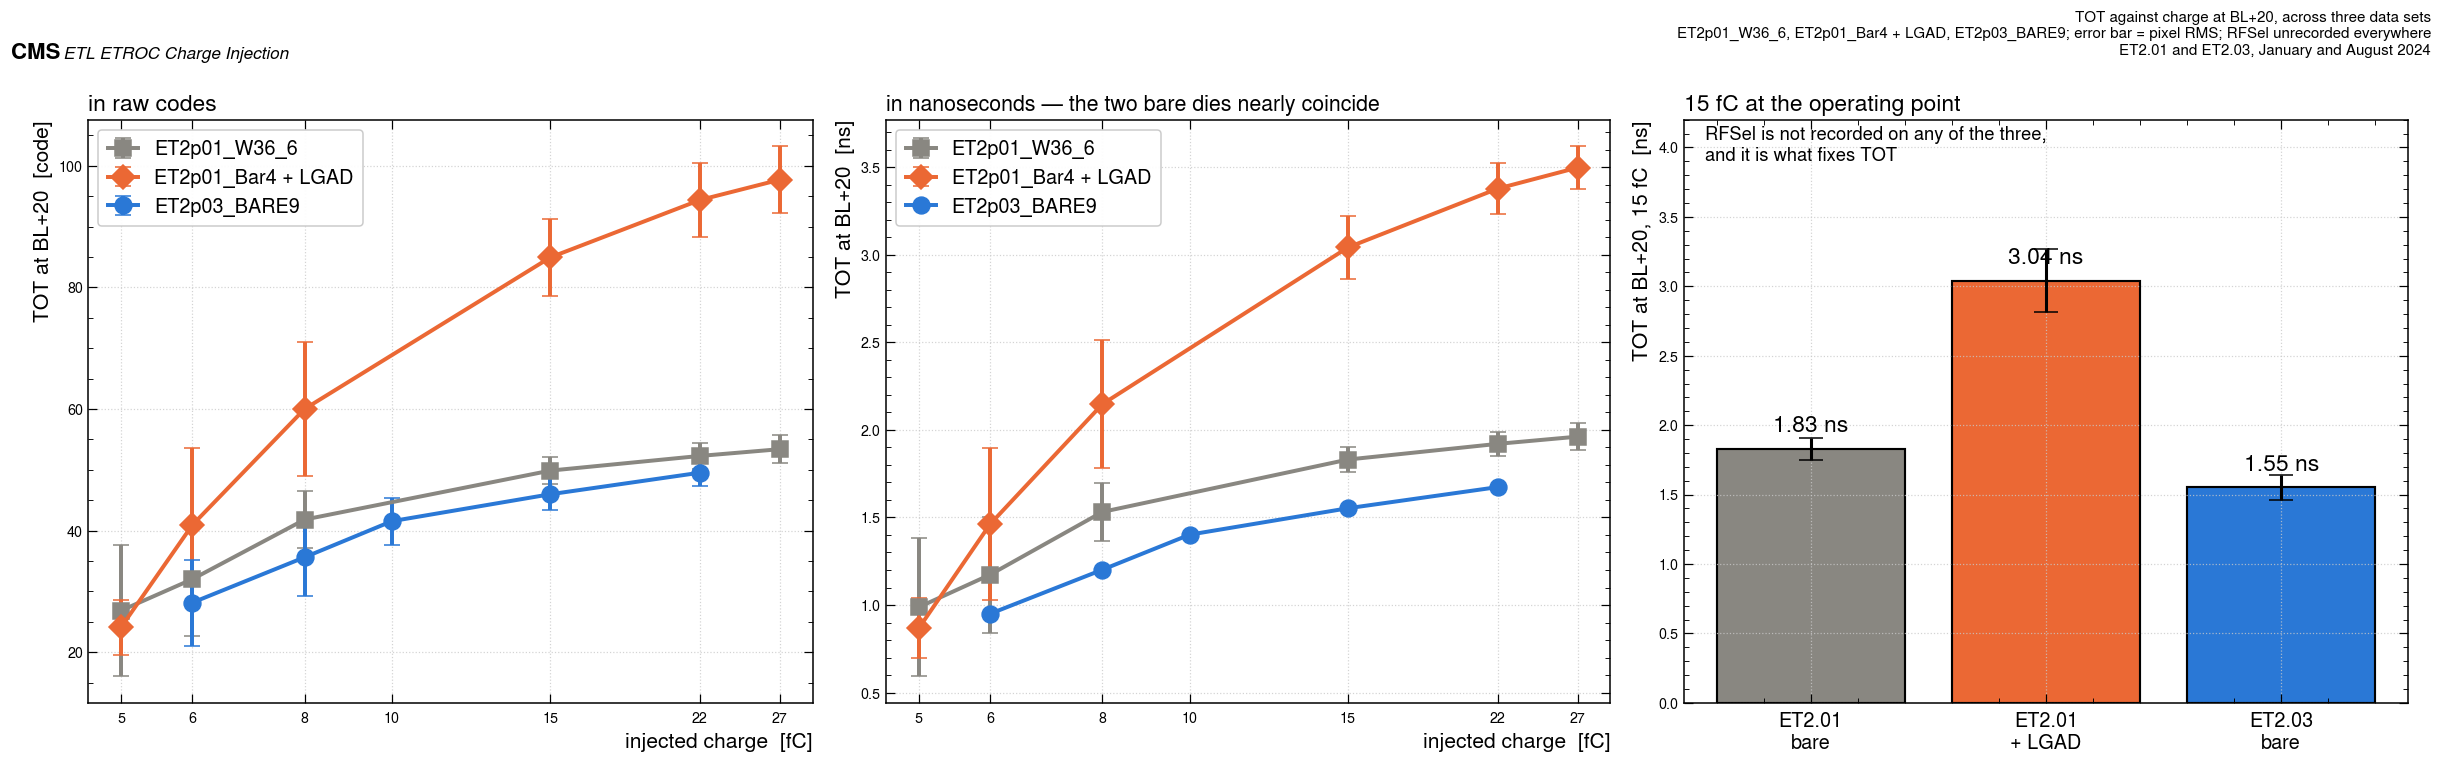

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for tab, ds in [(t01, K01), (th, K02), (t03, K03)]:
    ax.errorbar(tab.index, tab.tot_code_mean, yerr=tab.tot_code_pixel_rms, fmt="-", marker=SMK[ds],
                ms=11, lw=2.6, color=SCOL[ds], capsize=5, label=DIE[ds])
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(t01.index) + list(t03.index))))
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.legend(fontsize=13)
ax.set_title("in raw codes", loc="left", fontsize=15)

ax = axs[1]
for tab, ds in [(t01, K01), (th, K02), (t03, K03)]:
    ax.errorbar(tab.index, tab.tot_ns_mean, yerr=tab.tot_ns_pixel_rms if "tot_ns_pixel_rms" in tab else None,
                fmt="-", marker=SMK[ds], ms=11, lw=2.6, color=SCOL[ds], capsize=5, label=DIE[ds])
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(t01.index) + list(t03.index))))
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [ns]")
ax.legend(fontsize=13)
ax.set_title("in nanoseconds — the two bare dies nearly coincide", loc="left", fontsize=14)

ax = axs[2]
labels = ["ET2.01\nbare", "ET2.01\n+ LGAD", "ET2.03\nbare"]
vals = [t01.loc[15, "tot_ns_mean"], th.loc[15, "tot_ns_mean"], t03.loc[15, "tot_ns_mean"]]
errs = [t01.loc[15, "tot_code_pixel_rms"] * t01.loc[15, "tot_ns_mean"] / t01.loc[15, "tot_code_mean"],
        th.loc[15, "tot_code_pixel_rms"] * th.loc[15, "tot_ns_mean"] / th.loc[15, "tot_code_mean"],
        t03.loc[15, "tot_code_pixel_rms"] * t03.loc[15, "tot_ns_mean"] / t03.loc[15, "tot_code_mean"]]
ax.bar(range(3), vals, yerr=errs, capsize=8, color=[SCOL[K01], SCOL[K02], SCOL[K03]],
       edgecolor="black", lw=1.4)
for i, v in enumerate(vals):
    ax.text(i, v + 0.12, f"{v:.2f} ns", ha="center", fontsize=15)
ax.set_xticks(range(3))
ax.set_xticklabels(labels, fontsize=13)
ax.set_ylabel("TOT at BL+20, 15 fC  [ns]")
ax.set_ylim(0, 4.2)
ax.text(0.03, 0.93, "RFSel is not recorded on any of the three,\nand it is what fixes TOT",
        transform=ax.transAxes, fontsize=12)
ax.set_title("15 fC at the operating point", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "TOT against charge at BL+20, across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; error bar = pixel RMS; "
                 "RFSel unrecorded everywhere", scale=0.62,
             campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig4_tot")
plt.show()

## 6. TOA jitter at the operating point

The same warning as in every notebook of this folder, and it applies to all three data sets at
once: **the injection is synchronous with the clock and no sensor is generating the signal**, so
above about 8 fC the measured jitter closes on the TDC quantisation floor `LSB/√12` and is a
limit rather than a resolution. "Closes on" rather than "sits at": the `over_floor` column below
gives the ratio point by point, and at 15 fC it is 1.18, 2.02 and 1.69 on the three data sets —
only the bare ET2.01 is really at its floor. None of these numbers may be compared with a beam per-board time
resolution. The physics is in the low-charge rise.

The floors themselves differ, because one TOA code is `3.125 ns / CAL` and CAL differs between
the data sets, so each is drawn with its own.

In [13]:
j01 = J01.set_index("charge")
j03 = J03[(J03.config == CFG03) & (J03.offset == 20)].set_index("charge_fC")
jh = BVH[BVH.quantity.str.startswith("TOA jitter at BL+20")].copy()
jh["charge"] = [int(q.split(",")[-1].replace("fC", "").strip()) for q in jh.quantity]
jh = jh.set_index("charge")
fl01, fl03 = B01["quantisation_floor_ps"], B03["quantisation_floor_ps"]
flh = float(BVH[BVH.quantity == "TDC quantisation floor"].hybrid.iloc[0])
print("TDC quantisation floor:  ET2.01 bare %.2f ps   ET2.01+LGAD %.2f ps   ET2.03 bare %.2f ps"
      % (fl01, flh, fl03))
print("(one TOA code: %.1f, %.1f and %.1f ps, i.e. CAL %.0f, %.0f and %.0f)"
      % (B01["toa_lsb_ps"], flh * np.sqrt(12), B03["toa_lsb_ps"],
         B01["cal_median"], CAL_HYB, B03["cal_median"]))
JCMP = pd.DataFrame([
    dict(charge_fC=c, data_set=K01, jitter_ps=j01.loc[c, "mean"], pixel_rms=j01.loc[c, "std"],
         n_pixels=int(j01.loc[c, "size"]), floor_ps=fl01, over_floor=j01.loc[c, "mean"] / fl01)
    for c in j01.index] + [
    dict(charge_fC=c, data_set=K02, jitter_ps=float(jh.loc[c, "hybrid"]), pixel_rms=np.nan,
         n_pixels=9, floor_ps=flh, over_floor=float(jh.loc[c, "hybrid"]) / flh)
    for c in jh.index] + [
    dict(charge_fC=c, data_set=K03, jitter_ps=j03.loc[c, "jitter_mean"],
         pixel_rms=j03.loc[c, "jitter_pixel_rms"], n_pixels=int(j03.loc[c, "n_pixels"]),
         floor_ps=fl03, over_floor=j03.loc[c, "jitter_mean"] / fl03)
    for c in j03.index])
JCMP.to_csv(Q.OUTDIR / "xcamp_jitter_at_bl20.csv", index=False)
print()
print(JCMP.round(2).to_string(index=False))
print("\nNotebook 02 exports the hybrid's jitter at 8 and 15 fC only (through bare_vs_hybrid.csv),")
print("so the hybrid contributes two points here rather than a curve. Notebook 03's six-pixel")
print("means are pulled around by single pixels at low charge; its medians are")
print("  %s ps" % {int(c): round(v, 1) for c, v in B03["jitter_off20_median_by_charge"].items()})
print("against the means")
print("  %s ps" % {int(c): round(v, 1) for c, v in B03["jitter_off20_by_charge"].items()})

TDC quantisation floor:  ET2.01 bare 5.37 ps   ET2.01+LGAD 5.24 ps   ET2.03 bare 4.88 ps
(one TOA code: 18.6, 18.1 and 16.9 ps, i.e. CAL 168, 172 and 185)

 charge_fC      data_set  jitter_ps  pixel_rms  n_pixels  floor_ps  over_floor
       5.0   ET2.01 bare      23.88      13.12         9      5.37        4.45
       6.0   ET2.01 bare      22.07      16.00        12      5.37        4.11
       8.0   ET2.01 bare      10.78       3.02        12      5.37        2.01
      15.0   ET2.01 bare       6.36       3.01        12      5.37        1.18
      22.0   ET2.01 bare       7.42       2.72        12      5.37        1.38
      27.0   ET2.01 bare       6.61       3.23        12      5.37        1.23
       8.0 ET2.01 + LGAD      27.66        NaN         9      5.24        5.28
      15.0 ET2.01 + LGAD      10.58        NaN         9      5.24        2.02
       6.0   ET2.03 bare      22.69      12.42         5      4.88        4.65
       8.0   ET2.03 bare      13.09       5.34        

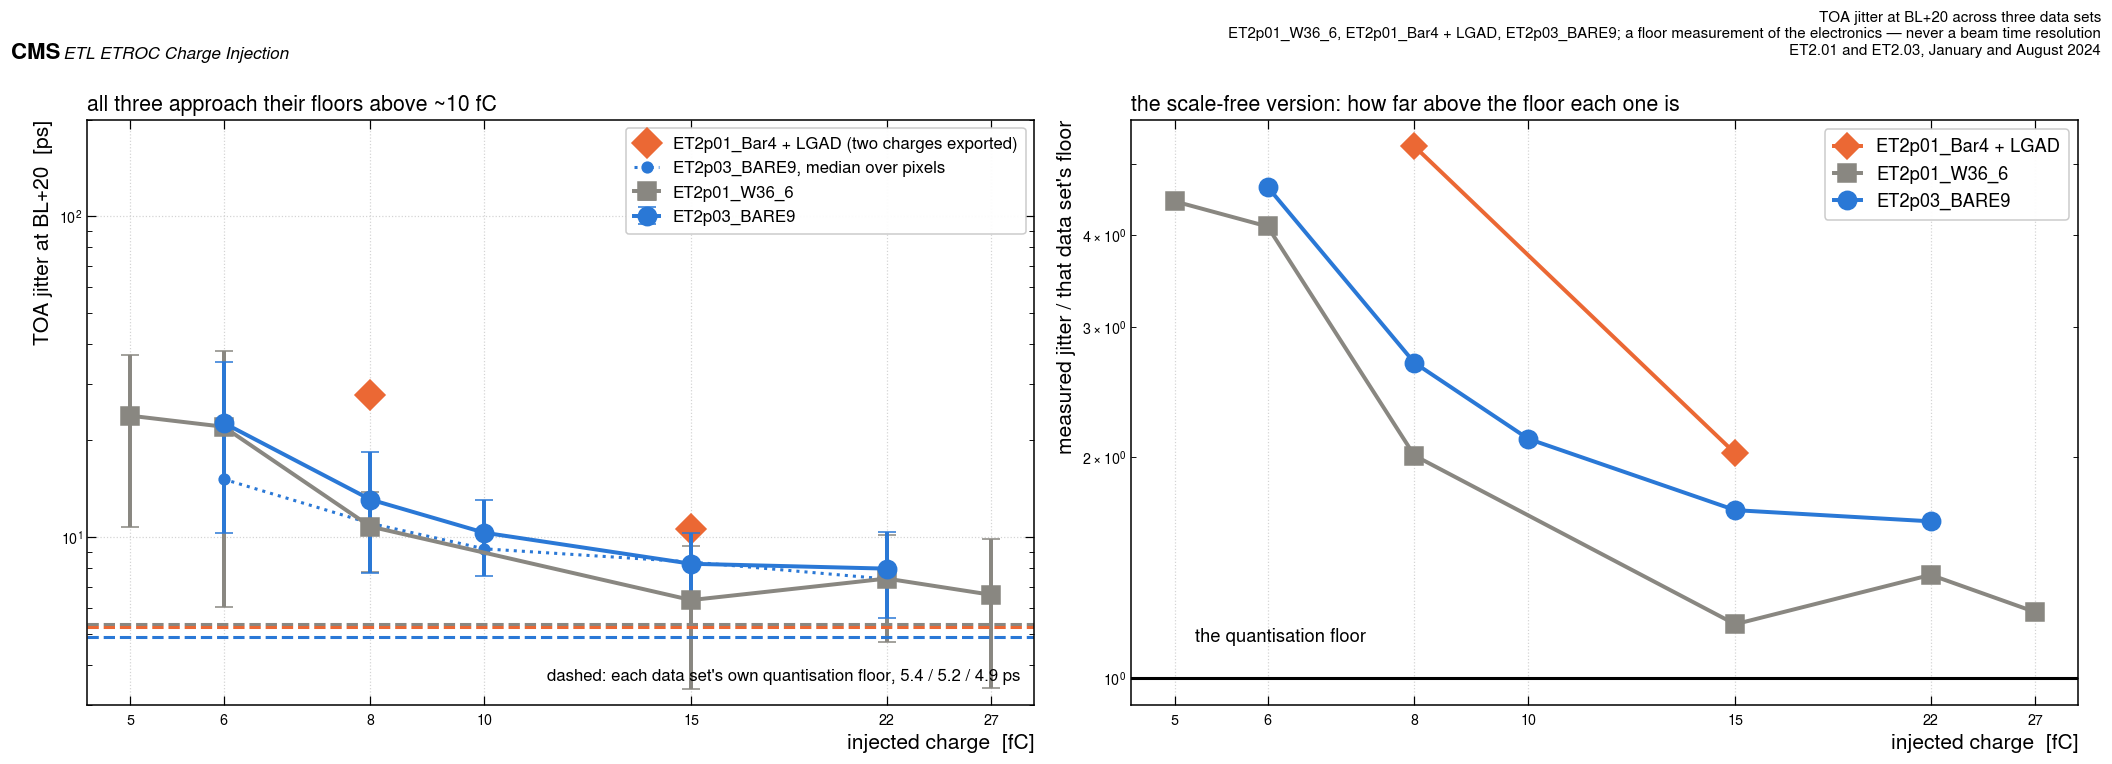

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
ax.errorbar(j01.index, j01["mean"], yerr=j01["std"], fmt="-", marker=SMK[K01], ms=12, lw=2.6,
            color=SCOL[K01], capsize=6, label=DIE[K01])
ax.plot(jh.index, jh.hybrid, "D", ms=14, color=SCOL[K02], label=DIE[K02] + " (two charges exported)")
ax.errorbar(j03.index, j03.jitter_mean, yerr=j03.jitter_pixel_rms, fmt="-", marker=SMK[K03],
            ms=12, lw=2.6, color=SCOL[K03], capsize=6, label=DIE[K03])
ax.plot(j03.index, j03.jitter_median, ":", marker="o", ms=7, lw=2.0, color=SCOL[K03],
        label=DIE[K03] + ", median over pixels")
for fl, ds in [(fl01, K01), (flh, K02), (fl03, K03)]:
    ax.axhline(fl, color=SCOL[ds], ls="--", lw=2.0)
ax.text(0.985, 0.035, "dashed: each data set's own quantisation floor, %.1f / %.1f / %.1f ps"
        % (fl01, flh, fl03), transform=ax.transAxes, fontsize=11, ha="right", va="bottom")
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(j01.index) + list(j03.index))))
ax.set_yscale("log")
ax.set_ylim(3, 200)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOA jitter at BL+20  [ps]")
ax.legend(fontsize=11)
ax.set_title("all three approach their floors above ~10 fC", loc="left", fontsize=14)

ax = axs[1]
for ds, sub in JCMP.groupby("data_set"):
    sub = sub.sort_values("charge_fC")
    ax.plot(sub.charge_fC, sub.over_floor, "-", marker=SMK[ds], ms=12, lw=2.6, color=SCOL[ds],
            label=DIE[ds])
ax.axhline(1.0, color="black", lw=2)
ax.text(5.2, 1.12, "the quantisation floor", fontsize=12)
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(j01.index) + list(j03.index))))
ax.set_yscale("log")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("measured jitter / that data set's floor")
ax.legend(fontsize=12)
ax.set_title("the scale-free version: how far above the floor each one is", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "TOA jitter at BL+20 across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; a floor measurement of the "
                 "electronics — never a beam time resolution",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig5_jitter")
plt.show()

## 7. The threshold edge, the noise width and ENC

Three related quantities, and it matters which is which.

* **σ**, the shared-σ S-curve width, is a *charge-injection* measurement of the discriminator
  edge, in DAC.
* **NW**, the autocalibration noise width, is an *accumulator* measurement made by the chip
  itself, also in DAC. It is not the same definition as σ and the ratio between them is a data
  point, not a conversion.
* **ENC = σ / gain**, in electrons, is the only one of the three that is **free of the DAC
  scale**, because the scale appears in both numerator and denominator. It is therefore the
  right quantity to compare across chip revisions, and it is what this section leads with.

Notebook 03 measures NW two ways — the full width at half maximum of its in-configuration noise
scan, available at every condition, and the one autocalibration map the August campaign left
behind. Only the second is the same definition as the January campaigns', so it is the map value
that is compared here and the FWHM that is carried alongside.

In [15]:
s01 = S01[(S01.dose == 0) & (S01.temp == 12)].iloc[0]
sh = GH.set_index("config").loc[HYB_PRIMARY]
s03 = S03[S03.config == CFG03].iloc[0]
NOISE = pd.DataFrame([
    dict(quantity="S-curve width σ", unit="DAC", **{K01: B01["sigma_dac"], K02: sh.sigma_dac, K03: s03.sigma_dac},
         scale_free="no — DAC units"),
    dict(quantity="gain", unit="DAC/fC", **{K01: B01["gain_dac_per_fc"], K02: sh.gain_dac_per_fc,
                                            K03: s03.gain_dac_per_fc}, scale_free="no — DAC units"),
    dict(quantity="ENC = σ / gain", unit="electrons", **{K01: B01["enc_e"], K02: sh.ENC_e, K03: s03.ENC_e},
         scale_free="YES — the DAC scale cancels"),
    dict(quantity="autocalibration NW (map)", unit="DAC",
         **{K01: B01["nw_dac"], K02: sh.NW_map, K03: B03["nw_map_dac"]}, scale_free="no — DAC units"),
    dict(quantity="noise-peak FWHM", unit="DAC", **{K01: np.nan, K02: np.nan, K03: B03["nw_fwhm_dac"]},
         scale_free="no — and only ET2.03 measured it"),
    dict(quantity="NW(map) / σ", unit="—",
         **{K01: B01["nw_dac"] / B01["sigma_dac"], K02: sh.NW_map / sh.sigma_dac,
            K03: B03["nw_map_dac"] / s03.sigma_dac}, scale_free="YES — a ratio of two DAC quantities"),
])
NOISE.to_csv(Q.OUTDIR / "xcamp_noise_and_enc.csv", index=False)
print(NOISE.round(3).to_string(index=False))
print("\nENC ratios:  ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.ENC_e / B01["enc_e"], s03.ENC_e / B01["enc_e"]))
print("sigma ratios: ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.sigma_dac / B01["sigma_dac"], s03.sigma_dac / B01["sigma_dac"]))
print("gain ratios:  ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.gain_dac_per_fc / B01["gain_dac_per_fc"], s03.gain_dac_per_fc / B01["gain_dac_per_fc"]))
enc03 = {int(k): round(v) for k, v in B03["enc_by_dose_va120"].items()}
enc01 = dict(zip(S01[S01.temp == -25].dose.astype(int), S01[S01.temp == -25].enc.round(0)))
print("\nENC against dose:  ET2.01 bare at −25 °C %s e−" % enc01)
print("                   ET2.03 bare at VA 1.20 V %s e−" % enc03)
print("ET2.03 ENC against the analog rail at 200 MRad: %s e−"
      % {float(r.va): round(r.ENC_e) for _, r in S03[(S03.chip == "ET2p03_BARE9") & (S03.dose == 200)].sort_values("va").iterrows()})

                quantity      unit  ET2.01 bare  ET2.01 + LGAD  ET2.03 bare                          scale_free
         S-curve width σ       DAC        0.920          0.930        1.120                      no — DAC units
                    gain    DAC/fC        9.416          5.957        8.256                      no — DAC units
          ENC = σ / gain electrons      609.838        974.471      846.721         YES — the DAC scale cancels
autocalibration NW (map)       DAC        3.167          4.444        4.167                      no — DAC units
         noise-peak FWHM       DAC          NaN            NaN        2.989    no — and only ET2.03 measured it
             NW(map) / σ         —        3.442          4.779        3.720 YES — a ratio of two DAC quantities

ENC ratios:  ET2.01+LGAD / ET2.01 bare  1.60      ET2.03 bare / ET2.01 bare  1.39
sigma ratios: ET2.01+LGAD / ET2.01 bare  1.01      ET2.03 bare / ET2.01 bare  1.22
gain ratios:  ET2.01+LGAD / ET2.01 bare  0.63     

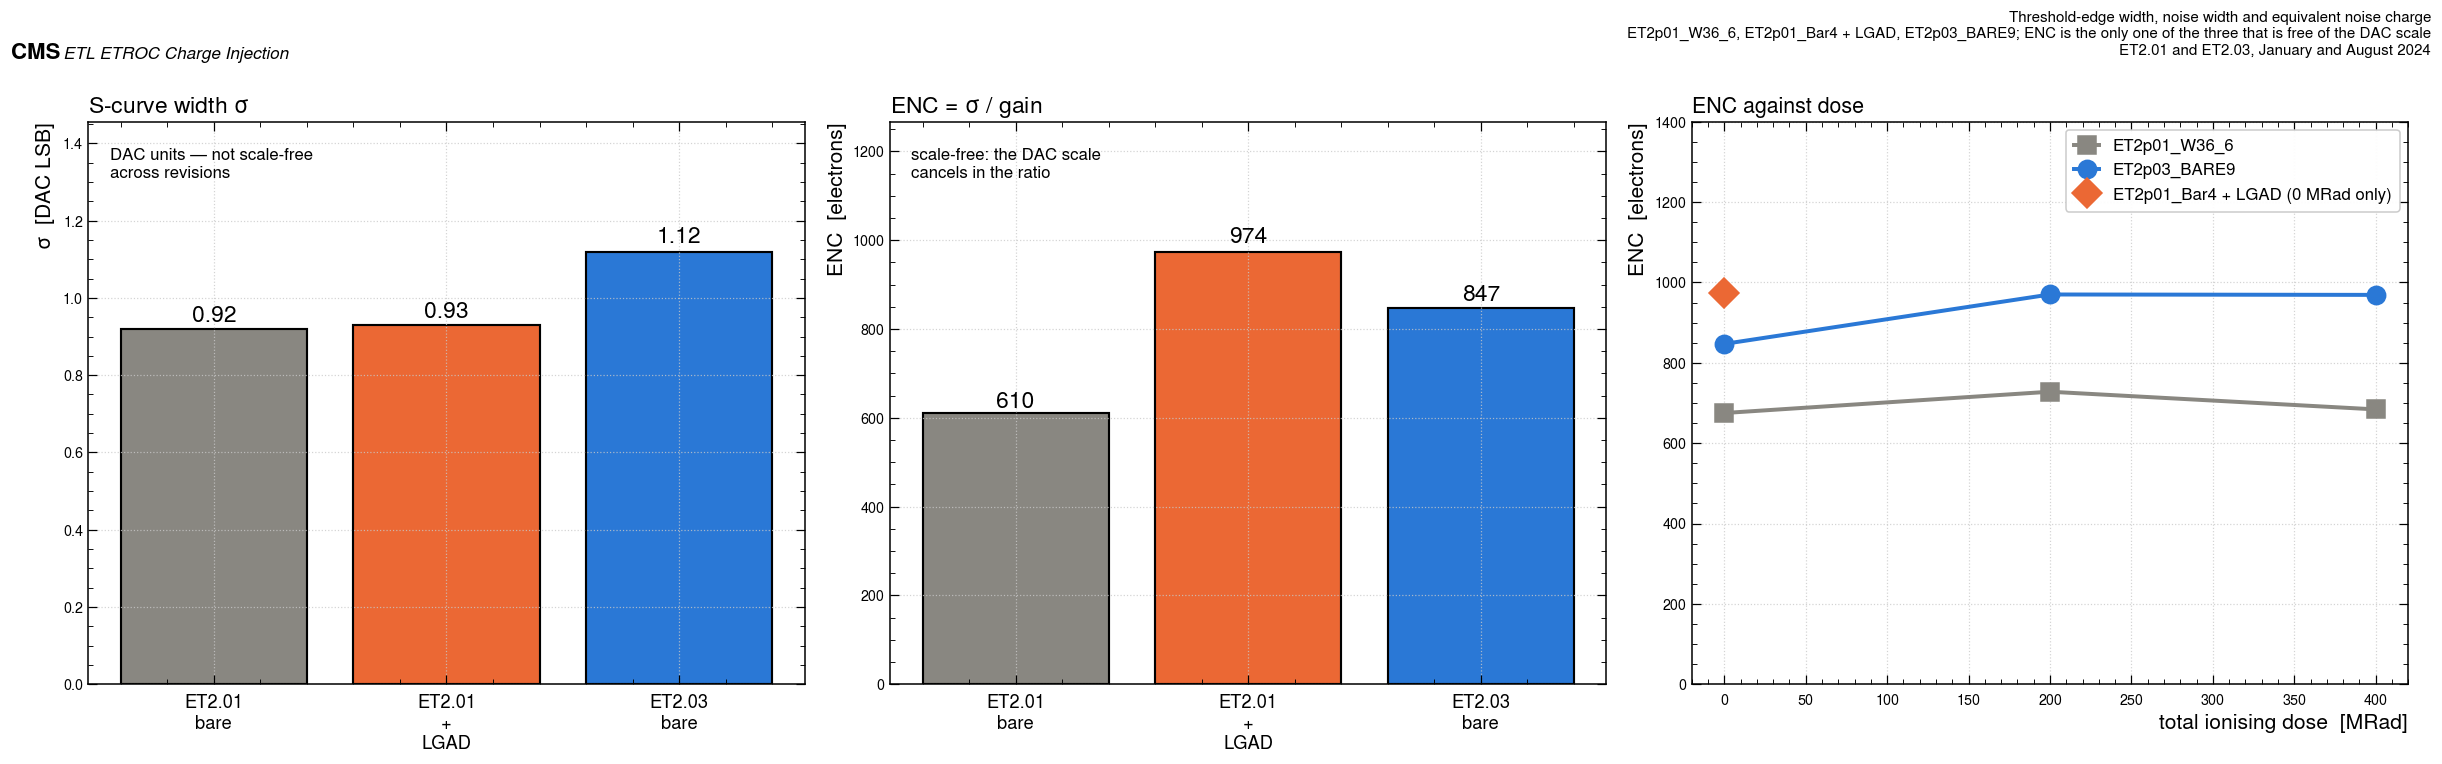

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
DS3 = [K01, K02, K03]


def three_bars(ax, vals, title, ylabel, fmt="%.2f", extra=None):
    ax.bar(range(3), vals, color=[SCOL[d] for d in DS3], edgecolor="black", lw=1.4)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.02, fmt % v, ha="center", fontsize=15)
    ax.set_xticks(range(3))
    ax.set_xticklabels([d.replace(" ", "\n") for d in DS3], fontsize=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals) * 1.30)
    ax.set_title(title, loc="left", fontsize=15)
    if extra:
        ax.text(0.03, 0.90, extra, transform=ax.transAxes, fontsize=11)


three_bars(axs[0], [B01["sigma_dac"], sh.sigma_dac, s03.sigma_dac],
           "S-curve width $\\sigma$", "$\\sigma$  [DAC LSB]",
           extra="DAC units — not scale-free\nacross revisions")
three_bars(axs[1], [B01["enc_e"], sh.ENC_e, s03.ENC_e], "ENC = $\\sigma$ / gain",
           "ENC  [electrons]", fmt="%.0f", extra="scale-free: the DAC scale\ncancels in the ratio")
ax = axs[2]
for ds, dd, vv in [(K01, sorted(enc01), [enc01[d] for d in sorted(enc01)]),
                   (K03, sorted(enc03), [enc03[d] for d in sorted(enc03)])]:
    ax.plot(dd, vv, "-", marker=SMK[ds], ms=12, lw=2.6, color=SCOL[ds], label=DIE[ds])
ax.plot([0], [sh.ENC_e], SMK[K02], ms=14, color=SCOL[K02], label=DIE[K02] + " (0 MRad only)")
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("ENC  [electrons]")
ax.set_ylim(0, 1400)
ax.legend(fontsize=11)
ax.set_title("ENC against dose", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Threshold-edge width, noise width and equivalent noise charge",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; ENC is the only one of the "
                 "three that is free of the DAC scale",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig6_noise_enc")
plt.show()

## 8. Everything that differs between the three, in one table

Nothing below is a result. It is the list of reasons why every result above is weaker than it
looks, written out so that a reader can judge each comparison for themselves.

In [17]:
DIFFS = pd.DataFrame([
    dict(axis="chip revision", et2p01_bare="ET2.01", hybrid="ET2.01", et2p03_bare="ET2.03",
         why_it_matters="2.02 fixed the on-chip voltage reference (~167 mV low on 2.01); 2.03 added dummy bump pads. Source: ETROC2 Reference Manual rev 0.6, revision history"),
    dict(axis="voltage reference", et2p01_bare="external 1.0 V", hybrid="external 1.0 V",
         et2p03_bare="internal generator, powered from VA; LOGGED through the irradiation (+4.7 % over 400 MRad)",
         why_it_matters="sets the DAC-to-mV scale; the ET2.03 reference was logged (notebook 03 §15), the transfer function was not, so absolute DAC comparisons remain unsafe"),
    dict(axis="die", et2p01_bare="W36_6", hybrid="Bar4", et2p03_bare="BARE9 (0/200/400 MRad); BARE7 quarantined (dose unknown)",
         why_it_matters="notebook 03 measures a large gain difference between two ET2.03 dies at 0 MRad; no second die of either revision has a usable dose step, so every dose sign is a one-die statement"),
    dict(axis="sensor", et2p01_bare="none", hybrid="LGAD, HV 210 V", et2p03_bare="none",
         why_it_matters="the hybrid's input capacitance is the point of notebook 02 and a confound everywhere else"),
    dict(axis="temperature", et2p01_bare="+12 °C (sweep), −25 °C (turn-off)", hybrid="0 °C",
         et2p03_bare="−23.6 °C, not scanned",
         why_it_matters="the two January sets disagree on the SIGN of the gain temperature coefficient; notebook 02 shows the hybrid series is internally consistent (untagged and tagged 0 C configs agree to 0.4 %) while the bare -25 C point is a different scan type, so the weight is on the hybrid; August cannot arbitrate"),
    dict(axis="analog rail VA", et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="0.85 / 1.00 / 1.20 / 1.40 V",
         why_it_matters="on ET2.03 the rail moves gain by ~2.8x — larger than every inter-campaign difference here"),
    dict(axis="digital rail VD", et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="1.20 V for every threshold scan; 0.90–1.45 V in the rail grid",
         why_it_matters="below 1.00 V the August chip produces no hits at all"),
    dict(axis="power mode", et2p01_bare="not recorded", hybrid="`highpower` (a directory tag)",
         et2p03_bare="not recorded",
         why_it_matters="notebook 02 shows the tag does not correspond to a repeatable supply current"),
    dict(axis="RFSel", et2p01_bare="not recorded", hybrid="not recorded", et2p03_bare="not recorded",
         why_it_matters="sets the feedback resistance and therefore gain AND TOT — the largest unquantified systematic in all three"),
    dict(axis="pixels", et2p01_bare="12: rows 0,1,3,12 × cols 2,8,14", hybrid="9: rows 2,8,14 × cols 2,8,14",
         et2p03_bare="6: rows 0,3,12 × cols 0,14",
         why_it_matters="no pixel is common to all three; every comparison is set-to-set, never pixel-to-pixel"),
    dict(axis="charges", et2p01_bare="5, 6, 8, 15, 22, 27 fC", hybrid="5, 6, 8, 15, 22, 27 fC",
         et2p03_bare="6, 8, 10, 15, 22 fC",
         why_it_matters="gain fits run 8–27 fC on the January sets and 8–22 fC on the August one"),
    dict(axis="dates", et2p01_bare="2024-01-11 to 01-19", hybrid="2024-01-11 to 01-19",
         et2p03_bare="2024-08-03 to 08-21",
         why_it_matters="seven months and a different facility; dose rate and annealing history are unrecorded on both"),
    dict(axis="turn-off estimator", et2p01_bare="interpolated 50 % of the trigger bit",
         hybrid="interpolated 50 % of the trigger bit",
         et2p03_bare="the search's own converged DAC — its binary search resolves a different feature",
         why_it_matters="notebook 03 measures the two definitions to agree to 0.0 ± 0.7 DAC wherever both are computable"),
    dict(axis="monitoring", et2p01_bare="LV supply log, 231 120 samples", hybrid="LV supply log + baseline history",
         et2p03_bare="none — one sentence of prose",
         why_it_matters="only the January sets can check whether the chip's operating point drifted during a scan"),
])
DIFFS.to_csv(Q.OUTDIR / "xcamp_conditions_differ.csv", index=False)
for _, r in DIFFS.iterrows():
    print("· %-20s  01: %-34s  02: %-34s  03: %s" % (r.axis, r.et2p01_bare, r.hybrid, r.et2p03_bare))
    print("  %s" % r.why_it_matters)

· chip revision         01: ET2.01                              02: ET2.01                              03: ET2.03
  2.02 fixed the on-chip voltage reference (~167 mV low on 2.01); 2.03 added dummy bump pads. Source: ETROC2 Reference Manual rev 0.6, revision history
· voltage reference     01: external 1.0 V                      02: external 1.0 V                      03: internal generator, powered from VA; LOGGED through the irradiation (+4.7 % over 400 MRad)
  sets the DAC-to-mV scale; the ET2.03 reference was logged (notebook 03 §15), the transfer function was not, so absolute DAC comparisons remain unsafe
· die                   01: W36_6                               02: Bar4                                03: BARE9 (0/200/400 MRad); BARE7 quarantined (dose unknown)
  notebook 03 measures a large gain difference between two ET2.03 dies at 0 MRad; no second die of either revision has a usable dose step, so every dose sign is a one-die statement
· sensor                01: none    

## 9. What a bench scan should settle, in order

Ranked by how much of the above each one would remove, not by how easy it is.

In [18]:
OPEN = pd.DataFrame([
    dict(rank=1, question="What is the threshold-DAC LSB, in millivolts, on each revision — and on ET2.03 how does it move with VA?",
         settled_by="A DAC transfer-function measurement: sweep the threshold DAC against an external voltmeter on one pixel, at VA 0.85/1.00/1.20/1.40 V, on an ET2.01 (or 2.02) board and an ET2.03 board.",
         what_it_removes="Everything in this notebook quoted in DAC becomes comparable across revisions: σ, NW, baseline shifts, gain in mV/fC. It is the single largest blocker."),
    dict(rank=2, question="What was RFSel on each of the three data sets, and how much does it move gain and TOT?",
         settled_by="Read RFSel back and scan it at fixed charge, recording TOT and turn-off at each setting.",
         what_it_removes="The TOT comparison of section 5 and the gain comparison of section 3, both of which are currently upper bounds on real differences."),
    dict(rank=3, question="Does the baseline-versus-dose sign flip follow the reference, the revision or the die?",
         settled_by="Two dies of the same revision through the same dose steps, with the reference switchable between internal and external on the same board.",
         what_it_removes="The four-way confound of section 2. This is the one measurement that would turn the folder's most striking observation into a result."),
    dict(rank=4, question="What is the temperature coefficient of preamp gain, and what is its sign? (notebook 02 argues the hybrid's +24 % on cooling is probably real and the bare die's -7.7 % is a scan-type artefact; unproven)",
         settled_by="One chip, one pixel set, a temperature scan from −25 to +25 °C at a fixed rail and a fixed bias, with the on-chip VTemp actually read out.",
         what_it_removes="The open disagreement between notebooks 01 and 02, which the August campaign cannot arbitrate because it did not scan temperature."),
    dict(rank=5, question="How much of the analog-rail dependence of gain is the front end and how much is the reference?",
         settled_by="The rail scan of notebook 03 repeated with an external reference, so that the DAC scale is fixed while VA moves.",
         what_it_removes="The ambiguity in section 13 of notebook 03, and with it the interpretation of the whole VA axis."),
    dict(rank=6, question="Is the chip-to-chip spread really ~20 % in gain, and how many dies does it take to know?",
         settled_by="The same six-pixel, five-charge scan on five or more dies of one revision at one condition.",
         what_it_removes="The die confound in every cross-campaign comparison here, currently bounded only by BARE7's un-irradiated numbers against BARE9's."),
    dict(rank=7, question="Does the ~5 % gain loss per 400 MRad hold below 8 fC, where the operating point actually lives?",
         settled_by="Charges of 2–8 fC in 1 fC steps, which needs a threshold scan fine enough to resolve turn-offs 10 DAC apart.",
         what_it_removes="The extrapolation in every `Q_min` number in this folder; no campaign has injected below 5 fC."),
    dict(rank=8, question="Does the sensor really cost gain without widening the threshold edge?",
         settled_by="A bare-and-bonded pair from the same wafer, same pixels, same rails, same temperature — the comparison notebook 02 could only approximate.",
         what_it_removes="The chip, temperature and pixel-set confounds on notebook 02's headline result."),
])
OPEN.to_csv(Q.OUTDIR / "xcamp_open_questions.csv", index=False)
for _, r in OPEN.iterrows():
    print("%d. %s" % (r["rank"], r.question))
    print("   settled by      : %s" % r.settled_by)
    print("   which would fix : %s\n" % r.what_it_removes)

1. What is the threshold-DAC LSB, in millivolts, on each revision — and on ET2.03 how does it move with VA?
   settled by      : A DAC transfer-function measurement: sweep the threshold DAC against an external voltmeter on one pixel, at VA 0.85/1.00/1.20/1.40 V, on an ET2.01 (or 2.02) board and an ET2.03 board.
   which would fix : Everything in this notebook quoted in DAC becomes comparable across revisions: σ, NW, baseline shifts, gain in mV/fC. It is the single largest blocker.

2. What was RFSel on each of the three data sets, and how much does it move gain and TOT?
   settled by      : Read RFSel back and scan it at fixed charge, recording TOT and turn-off at each setting.
   which would fix : The TOT comparison of section 5 and the gain comparison of section 3, both of which are currently upper bounds on real differences.

3. Does the baseline-versus-dose sign flip follow the reference, the revision or the die?
   settled by      : Two dies of the same revision through the same d

## 10. Summary

In [19]:
# The ET2.03 reference above is VA 1.20 V (supply) ~1.00 V at the chip, ~0.2 V UNDER nominal --
# forced, because it is the only analog setting with a 0 MRad money plot. Every absolute ET2.03
# number therefore comes from an under-volted chip. Where a 200 MRad value is acceptable, the same
# quantity at VA 1.40 V (supply), the ONE setting that is nominal at the chip, is put beside it.
CFG03_NOM = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 200)
                & (G03.va == Q.VA_NOMINAL_SUPPLY_V)].config.iloc[0]
gn = G03[G03.config == CFG03_NOM].iloc[0]
sn = S03[S03.config == CFG03_NOM].iloc[0]
tn = T03[(T03.config == CFG03_NOM) & (T03.offset == 20)].set_index("charge_fC")
jn = J03[(J03.config == CFG03_NOM) & (J03.offset == 20)].set_index("charge_fC")
on = O03[O03.config == CFG03_NOM].groupby("charge_fC").turnoff_offset.mean()
NOMNOTE = "VA 1.40 (supply) = ~1.20 V at chip, NOMINAL; 200 MRad"
print("\nThe ET2.03 columns of the table below come from two different rails:")
print("  `et2p03_bare`        %s  -- VA 1.20 V (supply) ~1.00 V at chip, ~0.2 V UNDER nominal,"
      % CFG03_LBL)
print("                       forced by the 0 MRad requirement (the only rail with a 0 MRad scan)")
print("  `et2p03_nominal_rail` %s  -- %s"
      % (G03[G03.config == CFG03_NOM].label.iloc[0], NOMNOTE))
print("  The two differ in BOTH rail and dose, so the second is not a correction of the first;")
print("  it is the nearest thing this campaign has to a nominal-condition absolute number.")
print("  A dash in `et2p03_nominal_rail` means the quantity has no VA 1.40 (supply) counterpart:")
print("  rows 2, 3 and 11 need a 0 MRad scan, which only VA 1.20 (supply) has, and row 7 is a")
print("  property of the reference-condition CAL rather than of a rail.\n")

SUM = pd.DataFrame([
    dict(n=1, quantity="Preamp gain (charge-to-threshold) at the reference condition", unit="DAC/fC",
         et2p01_bare=f"{B01['gain_dac_per_fc']:.2f} ± {B01['gain_sem']:.2f}",
         hybrid=f"{sh.gain_dac_per_fc:.2f} ± {sh.gain_sem:.2f}",
         et2p03_bare=f"{s03.gain_dac_per_fc:.2f} ± {G03[G03.config == CFG03].gain_sem.iloc[0]:.2f}",
         et2p03_nominal_rail=f"{gn.gain_dac_per_fc:.2f} ± {gn.gain_sem:.2f}",
         comparable="NO — DAC scale differs between revisions"),
    dict(n=2, quantity="Gain change, 0 → 400 MRad (paired per pixel)", unit="%",
         et2p01_bare=f"{f01:+.1f} ± {f01e:.1f} ({n01p} px)", hybrid="no dose series",
         et2p03_bare=f"{f03:+.1f} ± {f03e:.1f} ({n03p} px)",
         comparable="YES — a fractional change, same estimator on both"),
    dict(n=3, quantity="Baseline shift, 0 → 400 MRad", unit="DAC",
         et2p01_bare=f"{d01:+.1f} at −25 °C", hybrid="no dose series",
         et2p03_bare=f"{d03:+.1f} at VA 1.20 V", comparable="sign yes, magnitude no"),
    dict(n=4, quantity="Turn-off above baseline at 15 fC", unit="DAC",
         et2p01_bare=f"{o01.loc[15, 'mean']:.1f}", hybrid=f"{oh.loc[15, 'mean']:.1f}",
         et2p03_bare=f"{o03.loc[15, 'mean']:.1f}", et2p03_nominal_rail=f"{on[15]:.1f}",
         comparable="offset cancels, scale does not"),
    dict(n=5, quantity="TOT at BL+20, 15 fC", unit="ns",
         et2p01_bare=f"{t01.loc[15, 'tot_ns_mean']:.2f}", hybrid=f"{th.loc[15, 'tot_ns_mean']:.2f}",
         et2p03_bare=f"{t03.loc[15, 'tot_ns_mean']:.2f}",
         et2p03_nominal_rail=f"{float(tn.loc[15, 'tot_ns_mean']):.2f}",
         comparable="YES in ns — but RFSel unrecorded on all three"),
    dict(n=6, quantity="TOA jitter at BL+20, 15 fC", unit="ps",
         et2p01_bare=f"{j01.loc[15, 'mean']:.1f}", hybrid=f"{float(jh.loc[15, 'hybrid']):.1f}",
         et2p03_bare=f"{j03.loc[15, 'jitter_mean']:.1f}",
         et2p03_nominal_rail=f"{float(jn.loc[15, 'jitter_mean']):.1f}",
         comparable=("near the floor, ×%.2f / ×%.2f / ×%.2f of it — limits, not resolutions"
                     % tuple(JCMP.set_index(["data_set", "charge_fC"]).over_floor.loc[
                         [(K01, 15.0), (K02, 15.0), (K03, 15.0)]]))),
    dict(n=7, quantity="TDC quantisation floor", unit="ps", et2p01_bare=f"{fl01:.2f}",
         hybrid=f"{flh:.2f}", et2p03_bare=f"{fl03:.2f}", comparable="a property of the TDC and CAL"),
    dict(n=8, quantity="S-curve width σ", unit="DAC", et2p01_bare=f"{B01['sigma_dac']:.2f}",
         hybrid=f"{sh.sigma_dac:.2f}", et2p03_bare=f"{s03.sigma_dac:.2f}",
         et2p03_nominal_rail=f"{sn.sigma_dac:.2f}",
         comparable="NO — DAC scale differs between revisions"),
    dict(n=9, quantity="ENC = σ / preamp gain", unit="electrons", et2p01_bare=f"{B01['enc_e']:.0f}",
         hybrid=f"{sh.ENC_e:.0f}", et2p03_bare=f"{s03.ENC_e:.0f}",
         et2p03_nominal_rail=f"{sn.ENC_e:.0f}",
         comparable="YES — the only scale-free noise number"),
    dict(n=10, quantity="Autocalibration NW (map)", unit="DAC", et2p01_bare=f"{B01['nw_dac']:.2f}",
         hybrid=f"{sh.NW_map:.2f}", et2p03_bare=f"{B03['nw_map_dac']:.2f}",
         et2p03_nominal_rail="one map only, at 0 MRad",
         comparable="same definition, different DAC scale"),
    dict(n=11, quantity="Gain range over the analog rail 0.85 → 1.40 V", unit="DAC/fC",
         et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="%.2f → %.2f" % (r200.gain_dac_per_fc.iloc[0], r200.gain_dac_per_fc.iloc[-1]),
         comparable="only ET2.03 measured it — and it dwarfs every other difference here"),
])
SUM["et2p03_nominal_rail"] = SUM.et2p03_nominal_rail.fillna("—")
SUM = SUM[["n", "quantity", "unit", "et2p01_bare", "hybrid", "et2p03_bare",
           "et2p03_nominal_rail", "comparable"]]
SUM.to_csv(Q.OUTDIR / "xcamp_summary_numbers.csv", index=False)
print(SUM.to_string(index=False))


The ET2.03 columns of the table below come from two different rails:
  `et2p03_bare`        BARE9, 0 MRad, VA 1.20 V (supply)  -- VA 1.20 V (supply) ~1.00 V at chip, ~0.2 V UNDER nominal,
                       forced by the 0 MRad requirement (the only rail with a 0 MRad scan)
  `et2p03_nominal_rail` BARE9, 200 MRad, VA 1.40 V (supply)  -- VA 1.40 (supply) = ~1.20 V at chip, NOMINAL; 200 MRad
  The two differ in BOTH rail and dose, so the second is not a correction of the first;
  it is the nearest thing this campaign has to a nominal-condition absolute number.
  A dash in `et2p03_nominal_rail` means the quantity has no VA 1.40 (supply) counterpart:
  rows 2, 3 and 11 need a 0 MRad scan, which only VA 1.20 (supply) has, and row 7 is a
  property of the reference-condition CAL rather than of a rail.

 n                                                     quantity      unit        et2p01_bare         hybrid        et2p03_bare     et2p03_nominal_rail                                     

### The five things worth carrying away

1. **The baseline moves the opposite way with dose on the two dies compared, and the measured
   reference explains only half of the ET2.03 side.** ET2.01 bare (`W36_6`, fixed external
   reference): baseline +46 DAC over 400 MRad, preamp gain −6.5 ± 3.2 % (paired, twelve pixels).
   ET2.03 bare (`BARE9`): baseline −65 DAC (6-pixel in-configuration) or −80 DAC (256-pixel
   autocalibration maps) over the same dose, while its internal reference **rose by +4.7 %** in the
   campaign's own VRef log. Under the one assumption that the DAC full scale follows VRef, that
   rise accounts for −37 DAC; the remaining −29 (6-pixel) to −43 DAC (map) is the ET2.03 front end
   drifting *down*, where the ET2.01 front end drifted *up*. The sign difference therefore survives
   the reference correction and stays a one-die-per-revision result: BARE7, the only other
   irradiated die, has an unknown dose and is kept out. The ET2.03 preamp gain, corrected for the
   same scale change, is −0.7 ± 4.3 %, consistent with no loss.
2. **In DAC units both revisions lose of order five per cent of gain per 400 MRad, and on ET2.03 the
   second dose step repeats at every rail setting the campaign used** (the ET2.03 number is a
   DAC-scale artefact by item 1; the repeatability across rails still holds). The four 200 → 400 MRad steps
   come out at −5.25 ± 3.87, −5.39 ± 1.94, −5.34 ± 2.76 and −4.96 ± 2.04 % at VA 0.85, 1.00,
   1.20 and 1.40 V — a spread of 0.4 points against per-step standard errors of 1.9 to 3.9
   points. That is a consistency check, **not** four independent measurements: it is one die,
   the same six pixels and the same two dose states re-read at four supply settings, so the four
   steps share their pixel sample and their irradiation entirely. The campaign's own
   repeatability floor, ±0.7 % from the two independent 0 MRad acquisitions, bounds the
   acquisition-to-acquisition scatter and nothing else. The cell above prints all four.
3. **Under-volting the analog rail is a bigger lever than anything else measured in this
   folder.** Moving VA from 0.85 to 1.40 V *on the power supply* on one ET2.03 die changes the
   preamp gain by a factor of about 2.8 — larger than the bare-versus-hybrid difference, larger
   than the revision difference, larger than 400 MRad. But those settings are **~0.65 → ~1.20 V
   at the chip**: the scan runs from roughly half the nominal analog rail *up to* nominal and
   never above it, so this is a statement about **under-voltage sensitivity**, not about the
   chip's behaviour across a range around its operating point. Neither January campaign recorded
   its rails at all, so no absolute gain comparison between them is safe.
4. **ENC is the only noise number that survives the revision change**, because the DAC scale
   cancels in σ/gain: 610 e⁻ bare ET2.01, 974 e⁻ with an LGAD bonded, 847 e⁻ bare ET2.03. The
   σ values themselves — 0.92, 0.93 and 1.12 DAC — cannot be compared across revisions at all
   without a DAC transfer-function measurement, which is open question 1.
5. **Running the chip well below its nominal analog rail costs more than the dose does.** At
   VA 0.85 V (supply) ≈ 0.65 V at the chip, the ET2.03 die loses 17 % of its preamp gain over
   400 MRad against 5 % at VA 1.20 V (supply) ≈ 1.00 V at the chip, and
   its noise scan degenerates. On the digital rail, notebook 03 section 12 reports what the
   campaign's own `info.txt` recorded and what decoding those sub-runs blind reproduces: after
   200 MRad, **pixel auto-calibration failed at VD = 0.90 V**, and **at VD = 0.95 V the links and
   the injector failed even though the pixels calibrated** — `QInj` events empty but at the right
   BCIDs. Both sets of sub-runs decode to exactly zero hits.

---

## 11. Caveats specific to this notebook

1. **Nothing here is recomputed.** Every number is read from a table written by notebook 01, 02
   or 03. If one of those is re-run with a changed definition, this notebook must be re-run too;
   it has no independent access to the data.
2. **The hybrid contributes a point, not a curve, in several places.** Notebook 02 exports its
   TOA jitter at BL+20 only at 8 and 15 fC (through `bare_vs_hybrid.csv`), and it has no dose
   series at all, so sections 3, 6 and 7 carry it as a single marker rather than a line.
3. **The reference conditions are not matched, and cannot be.** Notebook 01's reference is
   0 MRad at +12 °C, notebook 02's is 0 °C with an LGAD at 210 V, notebook 03's is 0 MRad at
   −23.5 °C and VA 1.20 V. Section 8 is the full list; every figure caption says which is which.
4. **The two revisions' DAC scales are not known to be the same.** What ET2.03 demonstrably
   shows is that its DAC-referred **gain and baseline** move strongly with the analog rail — not
   that the DAC scale itself does. The internal reference is powered from VA (so the millivolts
   per code may track it) and so are the preamplifier bias currents (so the front-end gain may
   genuinely change); a ×2.8 gain swing would require a ×2.8 reference swing to be scale alone,
   which is not plausible, so a real front-end change is at least as likely. Nothing in this
   folder separates the two — that is open question 1, the DAC transfer function. Any comparison
   of an absolute DAC quantity here is labelled `NO` in the summary's `comparable` column and
   should be read as indicative only.
5. **RFSel is unrecorded on all three data sets**, so the TOT comparison in section 5 bounds a
   difference rather than measuring one.
6. **No cut is applied anywhere**, here or in the three notebooks this reads. What varies is
   coverage, and each source table carries its own `n`.